# 🏔️ The Optimizer Lab: Building and Racing Every Optimizer from Scratch

Welcome! If you have ever trained a machine learning model, you have seen loss numbers tick down on your screen. But what actually moves those numbers? How does a neural network adjust millions of weights to learn patterns?

The engine under the hood is an **optimization algorithm** (or **optimizer**).

In this interactive lab, we are going to:
1. Demystify the theory behind loss landscapes and gradients in plain English.
2. Build every major optimizer—**SGD**, **Momentum**, **Nesterov (NAG)**, **RMSProp**, **Adam**, and **AdamW**—completely from scratch using only NumPy.
3. Race them against each other on treacherous 2D mathematical test terrains.
4. Explore learning rates and decay schedules.
5. Benchmark them on a real computer vision model using PyTorch across multiple random seeds.
6. Uncover hidden failure modes where popular optimizers break down.

Let's begin our journey from zero to total confidence!

## 📚 The Living Glossary

Here is our master dictionary. Every time a new concept or term is introduced in this notebook, it is defined in plain language below.

| Term | Plain-English Definition |
| :--- | :--- |
| **Loss Function ($L$)** | A mathematical score showing how far our model's predictions are from reality (lower is better). |
| **Loss Landscape** | A multi-dimensional surface or topographic map of loss values across all possible parameter combinations. |
| **Parameter / Weight ($	heta$ or $w$)** | An adjustable dial inside the model that gets tuned to reduce the loss. |
| **Gradient ($
abla L$)** | A vector (arrow) pointing in the direction of steepest uphill climb on the loss surface. |
| **Learning Rate ($lpha$ or $\eta$)** | The step size multiplier; how far we move along the negative gradient direction in one step. |
| **Local Minimum** | A dip or valley floor where all immediate neighboring points have higher loss, but not necessarily the lowest on the entire map. |
| **Global Minimum** | The absolute lowest possible point on the entire loss landscape. |
| **Saddle Point** | A point where the slope is zero, but curves up in some directions and down in others (like a horse saddle). |
| **Sharp Minimum** | A narrow, steep pit. Moving even slightly off-center causes a massive spike in loss (generalizes poorly). |
| **Flat Minimum** | A broad, gentle basin. Small perturbations leave the loss low (generalizes well). |
| **Condition Number ($\kappa$)** | A ratio measuring how squashed or elongated a surface is: the ratio of maximum curvature to minimum curvature. |
| **Momentum** | A technique where the optimizer retains a running velocity of past gradients to roll smoothly through noise and ravines. |
| **Exponential Moving Average (EMA)** | A smoothed running average that gives more weight to recent values and decays older values exponentially. |
| **Second Moment ($v$ or $s$)** | The running average of squared gradients, tracking how volatile each individual parameter has been. |
| **Bias Correction** | A mathematical adjustment that prevents running averages from starting artificially close to zero at early steps. |
| **Weight Decay ($\lambda$)** | A regularization technique that gently shrinks weights toward zero to prevent overfitting. |
| **Decoupled Weight Decay** | Subtracting weight decay directly from weights rather than mixing it inside the adaptive gradient accumulator (the key innovation of AdamW). |

## 🔣 Mathematical Symbol Table

We will never show an equation without explaining every symbol in words. Refer to this table whenever you see math notation:

| Symbol | Name | Everyday Meaning | Typical Value |
| :--- | :--- | :--- | :--- |
| $	heta_t$ or $w_t$ | Theta / Weight at step $t$ | Current parameter value (our position on the mountain) | Real vector |
| $L(	heta)$ | Loss function | Current altitude / prediction penalty | Non-negative real scalar |
| $
abla L(	heta_t)$ or $g_t$ | Nabla $L$ / Gradient | Direction of steepest uphill climb at step $t$ | Vector of same shape as $	heta$ |
| $lpha$ or $\eta$ | Alpha / Learning Rate | Stride length multiplier | $10^{-4}$ to $0.1$ |
| $m_t$ or $v_t$ | First Moment / Velocity | Running average of past gradients (momentum buffer) | Vector of same shape as $	heta$ |
| $v_t$ or $s_t$ | Second Moment / Variance | Running average of past squared gradients | Vector of non-negative values |
| $eta$ or $eta_1$ | Beta 1 | Memory decay rate for past gradient directions | $0.9$ |
| $eta_2$ | Beta 2 | Memory decay rate for past gradient magnitudes | $0.999$ |
| $\epsilon$ | Epsilon | Microscopic safety buffer to prevent division by zero | $10^{-8}$ |
| $\lambda$ | Lambda | Weight decay penalty coefficient | $0.01$ |

---
## Step 1: Optimization Theory in Plain English

Before writing code, let's build an ironclad visual intuition of what optimization actually is. We will break this into five core ideas:
1. **The Loss Landscape**
2. **The Gradient**
3. **The Learning Rate**
4. **Terrain Hazards: Minima, Saddles, and Curvature**
5. **The Unifying Principle of Modern Optimizers**

### 1.1 The Loss Landscape

**1. The Idea in One Plain Sentence:**
A loss landscape is a mathematical elevation map that reveals how wrong our model's predictions are for every possible setting of its dials (parameters).

**2. A Real-Life Analogy:**
Imagine you are a hiker trapped in pitch-black night and thick fog in a mountain range. Your elevation represents your mistake: the higher up you are, the worse your predictions. Your goal is to descend to the lowest valley floor where elevation is zero.

**3. A Tiny Example with Real Numbers Worked by Hand:**
Suppose our model has just one parameter $w$, and its loss is given by:
$$L(w) = (w - 3)^2$$
Let's test three different positions:
- If $w = 5$: Loss is $(5 - 3)^2 = 2^2 = 4$. (Moderate mistake)
- If $w = 1$: Loss is $(1 - 3)^2 = (-2)^2 = 4$. (Moderate mistake)
- If $w = 3$: Loss is $(3 - 3)^2 = 0^2 = 0$. (Perfect prediction! We are at the bottom of the bowl.)

**4. The Math with Every Symbol Explained in Words:**
$$L: \mathbb{R}^d 	o \mathbb{R}, \quad 	heta \mapsto L(	heta)$$
- $	heta$: A list of $d$ numbers representing our model parameters.
- $L(	heta)$: A single scalar number representing total prediction error on our training data.
- Our goal: Find $	heta^* = rg\min_{	heta} L(	heta)$ (the parameter values giving minimum loss).

**What we are about to do and why:**
In the code cell below, we will create and plot a 2D loss bowl $L(w_1, w_2) = w_1^2 + 2 w_2^2$ using contour lines so you can see what a 2-parameter loss landscape looks like from above.

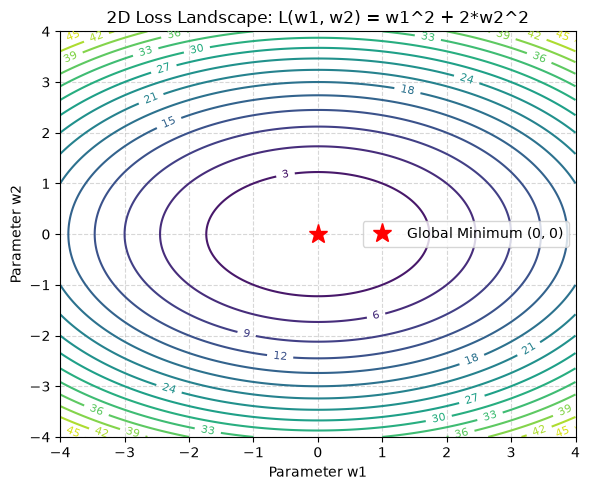

In [1]:
# Step 1.1 Code: Plotting a 2D Loss Landscape Contour Map
import numpy as np
import matplotlib.pyplot as plt

# Generate coordinate grid for parameters w1 and w2
w1 = np.linspace(-4, 4, 200)
w2 = np.linspace(-4, 4, 200)
W1, W2 = np.meshgrid(w1, w2)

# Compute loss surface: an elliptical bowl where w2 is twice as steep
Loss = W1**2 + 2 * W2**2

# Create contour plot
plt.figure(figsize=(6, 5))
contours = plt.contour(W1, W2, Loss, levels=15, cmap='viridis')
plt.clabel(contours, inline=True, fontsize=8)
plt.plot(0, 0, 'r*', markersize=14, label='Global Minimum (0, 0)')
plt.title("2D Loss Landscape: L(w1, w2) = w1^2 + 2*w2^2")
plt.xlabel("Parameter w1")
plt.ylabel("Parameter w2")
plt.grid(True, linestyle='--', alpha=0.5)
plt.legend()
plt.tight_layout()
plt.show()

**What we just saw:**
We generated a top-down contour map. Each ring represents a line of constant loss elevation.

**How to Read this Plot:**
- **Axes:** The horizontal axis is parameter $w_1$; the vertical axis is parameter $w_2$.
- **Colors & Rings:** Purple/blue concentric rings represent low loss; yellow rings represent high loss. The numbers printed on the lines are loss values.
- **What a Good Result Looks Like:** Reaching the center marked with the red star $(0, 0)$ where loss is $0$.
- **What a Bad Result Looks like:** Wandering outward into the high-numbered rings where loss exceeds $30$.
- **What this Tells Us:** The contours are oval-shaped (ellipses) because the $w_2$ direction has a steeper multiplier ($2$) than $w_1$ ($1$). Steeper directions curve faster!

**Common Beginner Mistake:**
Confusing accuracy with loss. You want accuracy to be as high as possible ($100\%$), but loss measures error, so you want loss to be as low as possible ($0$).

**Quick Check Yourself Question:**
> **Question:** If your neural network has 10 million parameters, how many numbers does the loss function spit out?
<details>
<summary>👉 Click to reveal answer</summary>

**Answer:** Exactly **one** single scalar number! Regardless of whether a model has 2 parameters or 200 billion parameters, the loss function aggregates all predictions into one real number measuring overall error.
</details>

### 1.2 The Gradient: The Slope Under Our Boots

**1. The Idea in One Plain Sentence:**
The gradient is a vector (an arrow) pointing in the direction of steepest uphill climb, with a length proportional to how steep the slope is.

**2. A Real-Life Analogy:**
You are the hiker standing on a hillside in the fog. You feel the ground beneath your boots. The gradient points directly straight uphill. To walk downhill toward safety, you must take steps in the **exact opposite** direction of the gradient!

**3. Prerequisite Refresher: Derivatives in 5 Lines**
> A derivative tells us how fast an output changes when an input nudges forward.
> For $f(x) = x^2$, the derivative is $f'(x) = 2x$.
> At $x = 3$, $f'(3) = 6$.
> This means if we nudge $x$ by $+0.01$, $f(x)$ increases by roughly $6 \times 0.01 = +0.06$.
> A positive derivative means moving right increases loss; a negative derivative means moving right decreases loss.

**4. A Tiny Example with Real Numbers Worked by Hand:**
Take our bowl function:
$$L(w_1, w_2) = w_1^2 + 2 w_2^2$$
We compute the partial derivatives (derivative with respect to each parameter while treating the other as a constant):
$$\frac{\partial L}{\partial w_1} = 2 w_1, \qquad \frac{\partial L}{\partial w_2} = 4 w_2$$
Now suppose we are standing at point $(w_1 = 2, w_2 = 3)$:
$$\nabla L(2, 3) = \begin{bmatrix} 2(2) \\ 4(3) \end{bmatrix} = \begin{bmatrix} 4 \\ 12 \end{bmatrix}$$
- **Uphill vector (Gradient):** $[+4, +12]^T$ (points up and right).
- **Downhill direction (Negative Gradient):** $[-4, -12]^T$ (points down and left toward the bottom!).

**5. The Math with Every Symbol Explained in Words:**
$$\nabla L(\theta) = \left[ \frac{\partial L}{\partial \theta_1}, \frac{\partial L}{\partial \theta_2}, \dots, \frac{\partial L}{\partial \theta_d} \right]^T$$
- $\nabla$ (Nabla): The gradient operator symbol.
- $\frac{\partial L}{\partial \theta_i}$: How much loss shifts when dial $\theta_i$ is wiggled.
- The gradient vector has the exact same number of dimensions as the parameter vector $\theta$.

**What we are about to do and why:**
We will compute the gradient at $(2, 3)$ and plot both the uphill gradient vector and the downhill stepping vector on top of the loss contours.

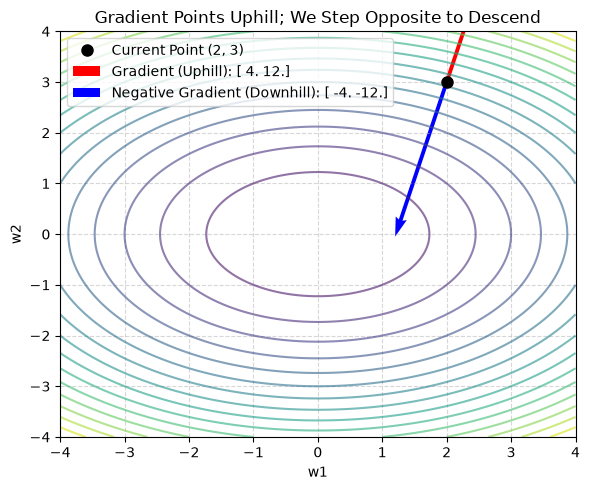

In [2]:
# Step 1.2 Code: Visualizing Gradient vs Negative Gradient Vector
# Current location on the landscape
curr_w = np.array([2.0, 3.0])
# Analytical gradient for L = w1^2 + 2*w2^2
grad = np.array([2.0 * curr_w[0], 4.0 * curr_w[1]])
neg_grad = -grad

plt.figure(figsize=(6, 5))
plt.contour(W1, W2, Loss, levels=15, cmap='viridis', alpha=0.6)
plt.plot(curr_w[0], curr_w[1], 'ko', markersize=8, label='Current Point (2, 3)')
# Plot gradient (uphill)
plt.quiver(curr_w[0], curr_w[1], grad[0], grad[1], color='red', 
           scale=40, label=f'Gradient (Uphill): {grad}')
# Plot negative gradient (downhill)
plt.quiver(curr_w[0], curr_w[1], neg_grad[0], neg_grad[1], color='blue', 
           scale=40, label=f'Negative Gradient (Downhill): {neg_grad}')
plt.title("Gradient Points Uphill; We Step Opposite to Descend")
plt.xlabel("w1"); plt.ylabel("w2"); plt.legend(); plt.grid(True, linestyle='--', alpha=0.5)
plt.tight_layout(); plt.show()

**What we just saw:**
The red arrow points uphill into regions of higher loss. The blue arrow points downhill directly toward lower contours.

**How to Read this Plot:**
- **Axes:** Coordinates $w_1$ and $w_2$.
- **Arrows:** The red vector is $\nabla L$; the blue vector is $-\nabla L$.
- **What this Tells Us:** To minimize error, we must always walk in the direction of the blue arrow (the negative gradient). Notice that the blue arrow is tilted more strongly downward along $w_2$ because $w_2$ is steeper!

**Common Beginner Mistake:**
Believing the gradient vector points directly toward the global minimum. It does not! The gradient only knows about the **immediate local slope under your feet**. If the valley curves like a snake, the gradient points down the local bank, not around the bend.

**Quick Check Yourself Question:**
> **Question:** If the gradient at your current position is $\nabla L = [0, 0]^T$, what direction will a gradient descent step take?
<details>
<summary>👉 Click to reveal answer</summary>

**Answer:** No step at all! The step size is $-\alpha \nabla L = -\alpha [0, 0]^T = [0, 0]^T$. When the slope is zero, standard gradient descent is completely stationary.
</details>

### 1.3 The Learning Rate: Our Stride Length

**1. The Idea in One Plain Sentence:**
The learning rate is a positive multiplier that controls how far we step along the downhill direction on each turn.

**2. A Real-Life Analogy:**
Think of the learning rate as your physical stride length.
- If your stride is microscopic ($1$ millimeter), you will safely descend, but it will take millions of years to reach the bottom.
- If your stride is gigantic ($50$ meters), you will leap clear across the valley and crash into the opposite cliff face.
- A well-tuned stride lets you jog down the mountain efficiently and safely.

**3. A Tiny Example with Real Numbers Worked by Hand:**
Let's minimize $L(w) = w^2$, starting at $w_0 = 4$.
The gradient is $\nabla L(w) = 2w$. At $w_0 = 4$, $\nabla L = 8$.
The update rule is:
$$w_{t+1} = w_t - \alpha \nabla L(w_t)$$
Let's compare three different learning rates:
- **Small ($\alpha = 0.1$):**
  $$w_1 = 4 - 0.1(8) = 4 - 0.8 = 3.2 \quad (\text{Loss drops from } 16 \to 10.24)$$
- **Just Right ($\alpha = 0.5$):**
  $$w_1 = 4 - 0.5(8) = 4 - 4.0 = 0.0 \quad (\text{Hits the exact minimum in one step!})$$
- **Overshooting ($\alpha = 1.0$):**
  $$w_1 = 4 - 1.0(8) = 4 - 8.0 = -4.0 \quad (\text{Bounces to the opposite side: } (-4)^2 = 16, \text{ stuck in loop})$$
- **Exploding / Diverging ($\alpha = 1.25$):**
  $$w_1 = 4 - 1.25(8) = 4 - 10.0 = -6.0 \quad (\text{Loss explodes from } 16 \to 36!)$$

**4. The Math with Every Symbol Explained in Words:**
$$\theta_{t+1} = \theta_t - \alpha g_t$$
- $\theta_{t+1}$: Our new position in parameter space at step $t+1$.
- $\theta_t$: Our current position at step $t$.
- $\alpha$: The learning rate (positive scalar, e.g. $0.01$).
- $g_t = \nabla L(\theta_t)$: The gradient evaluated at $\theta_t$.

**What we are about to do and why:**
We will simulate 10 steps of 1D gradient descent on $L(w) = w^2$ starting at $w = 4$ for three different learning rates ($lpha = 0.1, 0.9, 1.05$) to observe convergence, oscillation, and divergence side-by-side.

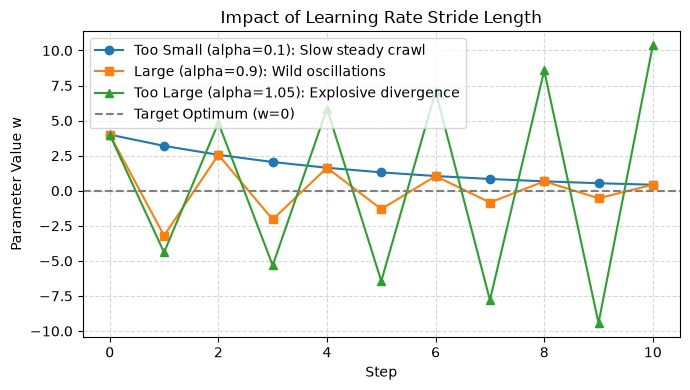

In [3]:
# Step 1.3 Code: Simulating Different Learning Rates on 1D Loss
def run_1d_descent(w_start, lr, steps=10):
    history = [w_start]
    w = w_start
    for _ in range(steps):
        grad = 2.0 * w       # Derivative of w^2 is 2w
        w = w - lr * grad     # Update rule
        history.append(w)
    return np.array(history)

steps = 10
hist_small = run_1d_descent(4.0, lr=0.1, steps=steps)
hist_oscillate = run_1d_descent(4.0, lr=0.9, steps=steps)
hist_diverge = run_1d_descent(4.0, lr=1.05, steps=steps)

plt.figure(figsize=(7, 4))
plt.plot(hist_small, 'o-', label='Too Small (alpha=0.1): Slow steady crawl')
plt.plot(hist_oscillate, 's-', label='Large (alpha=0.9): Wild oscillations')
plt.plot(hist_diverge, '^-', label='Too Large (alpha=1.05): Explosive divergence')
plt.axhline(0, color='gray', linestyle='--', label='Target Optimum (w=0)')
plt.xlabel("Step"); plt.ylabel("Parameter Value w"); plt.title("Impact of Learning Rate Stride Length")
plt.legend(); plt.grid(True, linestyle='--', alpha=0.5); plt.tight_layout(); plt.show()

**What we just saw:**
- With $\alpha = 0.1$ (blue circles), the parameter smoothly inches toward $0$.
- With $\alpha = 0.9$ (orange squares), the parameter oscillates wildly across $0$ before settling.
- With $\alpha = 1.05$ (green triangles), the parameter bounces wider and wider, exploding out of control.

**How to Read this Plot:**
- **Axes:** Step number (x-axis) vs. Parameter value (y-axis).
- **Good Result:** A line that quickly and smoothly flattens at $w=0$.
- **Bad Result:** A line that either crawls too slowly or blows up toward $\pm \infty$.
- **What this Tells Us:** The learning rate is the single most sensitive dial in machine learning. Set it too small and training takes forever; set it slightly too big and the model explodes.

**Common Beginner Mistake:**
Thinking that when a neural network outputs `NaN` (Not a Number), it has a bug in its code. In $95\%$ of cases, `NaN` loss simply means your learning rate is too large and weights diverged to infinity!

**Quick Check Yourself Question:**
> **Question:** If your loss is dropping, but at an excruciatingly slow crawl after 100 epochs, should you increase or decrease the learning rate?
<details>
<summary>👉 Click to reveal answer</summary>

**Answer:** You should carefully **increase** the learning rate (or use an adaptive optimizer with momentum) so each step covers more ground.
</details>

### 1.4 Terrain Hazards: Local Minima, Saddles, and Sharp vs. Flat Valleys

**1. The Idea in One Plain Sentence:**
Real loss landscapes are not smooth symmetrical bowls; they are riddled with deceptive plateaus, saddle passes, and narrow canyons that affect how well a model generalizes.

**2. A Real-Life Analogy:**
- **Global Minimum:** The deepest trench on Earth (Mariana Trench).
- **Local Minimum:** A small puddle trapped high on a ridge. If you step in any direction, you go uphill, but you are not at the bottom of the world.
- **Saddle Point:** A mountain pass between two peaks (looks like a horse saddle). Going north/south climbs uphill; going east/west descends downhill. Right at the pass center, the ground is dead flat ($
abla L = 0$).
- **Sharp vs. Flat Minima:**
  - *Sharp Minimum:* A tight, razor-sharp crevasse. If your test data is even slightly different from your training data, your position falls off the edge and loss skyrockets.
  - *Flat Minimum:* A wide, grassy valley floor. If test data causes a slight shift, you are still at the bottom and loss stays low!

**3. A Tiny Example with Real Numbers Worked by Hand:**
Consider the saddle function:
$$f(x, y) = x^2 - y^2$$
Gradient:
$$\nabla f(x, y) = [2x, -2y]^T$$
At $(0, 0)$:
$$\nabla f(0, 0) = [0, 0]^T$$
Even though the gradient is zero:
- If we move along $x$ (e.g. $x = 0.1, y = 0$): $f = (0.1)^2 = +0.01$ (uphill!).
- If we move along $y$ (e.g. $x = 0, y = 0.1$): $f = -(0.1)^2 = -0.01$ (downhill!).
This proves $(0, 0)$ is neither a minimum nor a maximum—it is a **saddle point**.

**What we are about to do and why:**
We will visualize both hazards in code: (1) a 3D saddle point surface where gradient vanishes, and (2) a comparison between a sharp minimum and a flat minimum under a slight data perturbation.

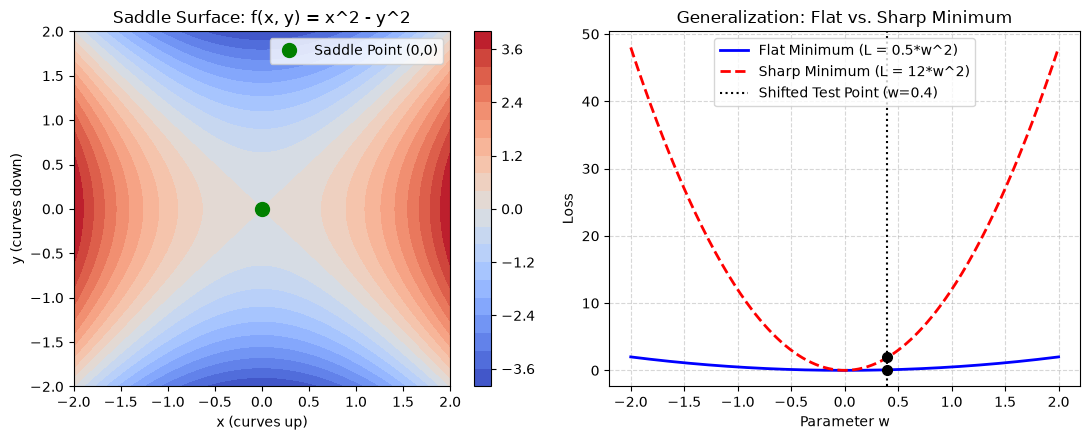

In [4]:
# Step 1.4 Code: Visualizing Saddle Points and Flat vs Sharp Minima
x = np.linspace(-2, 2, 100)
y = np.linspace(-2, 2, 100)
X, Y = np.meshgrid(x, y)
Z_saddle = X**2 - Y**2

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 4.5))

# Plot 1: Saddle Point Contour
cp = ax1.contourf(X, Y, Z_saddle, levels=20, cmap='coolwarm')
ax1.plot(0, 0, 'go', markersize=10, label='Saddle Point (0,0)')
ax1.set_title("Saddle Surface: f(x, y) = x^2 - y^2")
ax1.set_xlabel("x (curves up)"); ax1.set_ylabel("y (curves down)"); ax1.legend()
plt.colorbar(cp, ax=ax1)

# Plot 2: Sharp vs Flat Minimum Generalization
w = np.linspace(-2, 2, 200)
loss_flat = 0.5 * w**2
loss_sharp = 12.0 * w**2
shift = 0.4 # Small shift between train and test distribution
ax2.plot(w, loss_flat, 'b-', linewidth=2, label='Flat Minimum (L = 0.5*w^2)')
ax2.plot(w, loss_sharp, 'r--', linewidth=2, label='Sharp Minimum (L = 12*w^2)')
ax2.plot([shift, shift], [0.5*shift**2, 12*shift**2], 'ko', markersize=7)
ax2.axvline(shift, color='k', linestyle=':', label=f'Shifted Test Point (w={shift})')
ax2.set_title("Generalization: Flat vs. Sharp Minimum")
ax2.set_xlabel("Parameter w"); ax2.set_ylabel("Loss"); ax2.legend()
ax2.grid(True, linestyle='--', alpha=0.5)

plt.tight_layout(); plt.show()

**What we just saw:**
- In the left plot, $(0,0)$ has zero slope, but escaping along $y$ leads to much lower values. Plain gradient descent can get stuck here or crawl at a snail's pace!
- In the right plot, when test data nudges the parameter by $+0.4$, the flat minimum (blue) barely registers any error ($0.08$), while the sharp minimum (red) explodes to error $1.92$.

**How to Read this Plot:**
- **Left Plot:** Saddle surface contours. Blue represents valleys; red represents ridges. The green point is dead-center.
- **Right Plot:** 1D cross-section showing loss as parameters deviate from optimal.
- **What this Tells Us:** Optimization is not just about finding *any* zero-loss point. We specifically want optimizers that find **broad, flat valleys** because flat valleys generalize well to real-world test data!

**Common Beginner Mistake:**
Believing that in deep networks, getting trapped in bad local minima is the main reason models fail. In modern high-dimensional neural nets, true local minima are usually close in value to the global minimum. The real culprits that stall training are **saddle points** and **steep ravines**!

**Quick Check Yourself Question:**
> **Question:** Why do modern optimizers like Momentum and Adam escape saddle points much faster than plain SGD?
<details>
<summary>👉 Click to reveal answer</summary>

**Answer:** Because Momentum preserves past velocity! Even if the gradient hits zero right at the saddle point, the momentum buffer carries velocity from previous steps, rolling the optimizer right past the flat plateau.
</details>

### 1.5 The Unifying Idea of Modern Optimizers

Now, here is the master insight that ties this entire lab together. Every modern optimizer—from simple SGD to cutting-edge AdamW—is just a variation of one single master formula:

$$\text{Parameter Update} = -\alpha \cdot \Big[ \text{Per-Parameter Adaptive Scaling} \Big] \cdot \Big[ \text{Memory of Past Gradients} \Big]$$

Let's see how each famous optimizer builds upon this foundation:

1. **SGD (Stochastic Gradient Descent):**
   - Memory: None (only uses current gradient $g_t$).
   - Adaptive Scaling: None (uses the exact same learning rate $lpha$ for all parameters).
2. **SGD + Momentum:**
   - Memory: **YES!** Uses an Exponential Moving Average (EMA) of past gradients (like a heavy rolling bowling ball).
   - Adaptive Scaling: None.
3. **Nesterov Accelerated Gradient (NAG):**
   - Memory: **YES!** Looks ahead in the direction of momentum before measuring the gradient.
   - Adaptive Scaling: None.
4. **RMSProp:**
   - Memory: None on direction.
   - Adaptive Scaling: **YES!** Divides each coordinate by the square root of recent gradient magnitudes. Steep parameters take smaller steps; shallow parameters take bigger steps!
5. **Adam (Adaptive Moment Estimation):**
   - Memory: **YES!** Tracks first moment (momentum).
   - Adaptive Scaling: **YES!** Tracks second moment (RMSProp scaling).
   - Plus **Bias Correction** to fix startup lag.
6. **AdamW:**
   - Adam with **Decoupled Weight Decay**: shrinks weights directly without distorting the adaptive gradient history.

Here is the lineage tree in a simple diagram:

```
           Plain SGD (Only current gradient gt)
                      │
        ┌─────────────┴─────────────┐
        ▼                           ▼
Add Momentum Memory           Add Per-Parameter Scaling
 (SGD + Momentum, NAG)                (RMSProp)
        │                           │
        └─────────────┬─────────────┘
                      ▼
               Combine Both!
                  (Adam)
                      │
                      ▼
           Decouple Weight Decay
                 (AdamW)
```

### 📝 Step 1 Recap

**Recap in 3 Bullets:**
1. A **loss landscape** is an elevation map of errors; the **gradient** tells us which way is steepest uphill, and we step in the opposite direction scaled by the **learning rate**.
2. Loss surfaces are filled with hazards like **saddle points** (flat passes) and **ill-conditioned ravines** where standard gradient descent struggles.
3. Every advanced optimizer combines two tricks: **momentum memory** (to power through flats and smooth oscillations) and **per-parameter adaptive scaling** (to equalize fast and slow coordinates).

> 💡 **If you remember only one thing:**
> Optimization is simply deciding **which direction to face** (using current slope and past momentum) and **how big of a stride to take for each individual parameter** (using adaptive scale and learning rate).

---
## Step 2: Implement Every Optimizer From Scratch in NumPy

Now comes the fun part: we are going to build the engine of modern deep learning with our own hands.

For each optimizer, we will follow our strict 7-part pedagogical framework:
1. **The idea in ONE plain sentence**
2. **A real-life analogy**
3. **A tiny example with real numbers worked by hand (steps 1–3)**
4. **The math with EVERY symbol explained in words**
5. **The code explained line by line**
6. **One common beginner mistake**
7. **One quick "check yourself" question**

We will implement:
- **SGD** (Stochastic Gradient Descent)
- **SGD + Momentum**
- **Nesterov Accelerated Gradient (NAG)**
- **RMSProp**
- **Adam** (with bias correction)
- **AdamW** (with decoupled weight decay)

### 2.1 Plain Stochastic Gradient Descent (SGD)

**1. The Idea in One Plain Sentence:**
Plain SGD nudges each parameter in the opposite direction of its immediate gradient, scaled by the learning rate.

**2. A Real-Life Analogy:**
A hiker taking steps with no memory whatsoever—at each second, they pause, feel the slope right under their shoes, take one stride downhill, and immediately forget where they just came from.

**3. A Tiny Example with Real Numbers Worked by Hand:**
Let $L(w) = w^2$, so the gradient is $g(w) = 2w$.
Let learning rate $\alpha = 0.1$, starting at $w_0 = 5.0$:
- **Step 1:**
  - Gradient: $g_0 = 2(5.0) = 10.0$
  - Update: $w_1 = w_0 - \alpha g_0 = 5.0 - (0.1)(10.0) = 5.0 - 1.0 = \mathbf{4.0}$
- **Step 2:**
  - Gradient: $g_1 = 2(4.0) = 8.0$
  - Update: $w_2 = w_1 - \alpha g_1 = 4.0 - (0.1)(8.0) = 4.0 - 0.8 = \mathbf{3.2}$
- **Step 3:**
  - Gradient: $g_2 = 2(3.2) = 6.4$
  - Update: $w_3 = w_2 - \alpha g_2 = 3.2 - (0.1)(6.4) = 3.2 - 0.64 = \mathbf{2.56}$

**4. The Math with Every Symbol Explained in Words:**
$$w_{t+1} = w_t - \alpha g_t$$
- $w_{t+1}$: Updated parameter at step $t+1$.
- $w_t$: Current parameter at step $t$.
- $\alpha$: Learning rate (stride length).
- $g_t = \nabla L(w_t)$: Current gradient vector.

**What we are about to do and why:**
We will implement the `SGD` optimizer class in NumPy and test it on $L(w)=w^2$ to verify that our code produces the exact numbers we just calculated by hand ($4.0, 3.2, 2.56$).

In [5]:
# Step 2.1 Code: Plain SGD Optimizer Implementation
class SGD:
    def __init__(self, lr=0.01):
        self.lr = lr  # Learning rate (step size multiplier)

    def step(self, w, grad):
        # Update rule: w_new = w_old - lr * gradient
        return w - self.lr * grad

# Verify on our hand-worked example: L(w) = w^2, w0 = 5.0, lr = 0.1
opt_sgd = SGD(lr=0.1)
w = 5.0
print("SGD Hand-Verification Steps:")
for t in range(1, 4):
    g = 2.0 * w
    w = opt_sgd.step(w, g)
    print(f"  Step {t}: w = {w:.4f}")

SGD Hand-Verification Steps:
  Step 1: w = 4.0000
  Step 2: w = 3.2000
  Step 3: w = 2.5600


**What we just saw:**
The output shows `Step 1: 4.0000`, `Step 2: 3.2000`, `Step 3: 2.5600`. Our implementation perfectly matches our hand calculations!

**Line-by-Line Code Explanation:**
- `__init__(self, lr=0.01)`: Stores the user-chosen learning rate scalar.
- `step(self, w, grad)`: Receives current parameters `w` and gradient `grad`, subtracts `lr * grad`, and returns the updated parameter vector.

**Common Beginner Mistake:**
Confusing "Stochastic" Gradient Descent with randomness in the update rule itself. The update rule is $100\%$ deterministic! The word "stochastic" comes purely from computing the gradient on a random mini-batch of training examples rather than the entire dataset.

**Quick Check Yourself Question:**
> **Question:** If the gradient is negative ($g_t < 0$), does the parameter increase or decrease?
<details>
<summary>👉 Click to reveal answer</summary>

**Answer:** It **increases**! Subtracting a negative number adds to the parameter: $w_{t+1} = w_t - \alpha (-|g|) = w_t + \alpha |g|$. This is correct because a negative slope means the function goes down as you move to the right.
</details>

### 2.2 SGD + Momentum

**1. The Idea in One Plain Sentence:**
Momentum maintains a running velocity of past gradients, allowing the optimizer to accelerate along consistent downhill directions and dampen wild sideways bounces.

**2. A Real-Life Analogy:**
A heavy iron bowling ball rolling down a bumpy hill. Small bumps and sideways ruts won't stop it or deflect it wildly because its accumulated physical momentum powers it forward along the main downhill slope.

**3. Prerequisite Refresher: Exponential Moving Average (EMA) in 5 Lines**
> An EMA computes a running average where recent events matter more than older events:
> $$v_t = \beta v_{t-1} + (1 - \beta) x_t$$
> If $\beta = 0.9$, current velocity retains $90\%$ of past momentum and adds $10\%$ of the new signal.
> In deep learning momentum, we typically write $v_t = \beta v_{t-1} + g_t$ or $v_t = \beta v_{t-1} + \alpha g_t$. Both formulations give the ball persistent inertia!

**4. A Tiny Example with Real Numbers Worked by Hand:**
Let $L(w) = w^2, g = 2w, \alpha = 0.1, \beta = 0.9, w_0 = 5.0, v_0 = 0.0$.
Formula: $v_t = \beta v_{t-1} + g_t, \quad w_t = w_{t-1} - \alpha v_t$.
- **Step 1:**
  - Gradient: $g_0 = 2(5.0) = 10.0$
  - Velocity: $v_1 = 0.9(0.0) + 10.0 = \mathbf{10.0}$
  - Update: $w_1 = 5.0 - 0.1(10.0) = 5.0 - 1.0 = \mathbf{4.0}$
- **Step 2:**
  - Gradient: $g_1 = 2(4.0) = 8.0$
  - Velocity: $v_2 = 0.9(10.0) + 8.0 = 9.0 + 8.0 = \mathbf{17.0}$
  - Update: $w_2 = 4.0 - 0.1(17.0) = 4.0 - 1.7 = \mathbf{2.3}$
- **Step 3:**
  - Gradient: $g_2 = 2(2.3) = 4.6$
  - Velocity: $v_3 = 0.9(17.0) + 4.6 = 15.3 + 4.6 = \mathbf{19.9}$
  - Update: $w_3 = 2.3 - 0.1(19.9) = 2.3 - 1.99 = \mathbf{0.31}$

*Look at the dramatic difference:* After 3 steps, plain SGD was only at $2.56$, but Momentum accelerated all the way to $0.31$!

**5. The Math with Every Symbol Explained in Words:**
$$v_{t+1} = \beta v_t + g_t$$
$$w_{t+1} = w_t - \alpha v_{t+1}$$
- $v_t$: Velocity vector representing accumulated past gradient directions.
- $\beta$: Momentum decay factor (usually $0.9$, keeping $90\%$ of past velocity).
- $g_t$: Current gradient vector.
- $\alpha$: Learning rate.

**What we are about to do and why:**
We will implement the `Momentum` optimizer class in NumPy and test it on the same 3-step hand calculation to verify that $w_3 = 0.3100$.

In [6]:
# Step 2.2 Code: SGD + Momentum Implementation
class Momentum:
    def __init__(self, lr=0.01, beta=0.9):
        self.lr = lr        # Learning rate stride
        self.beta = beta    # Momentum decay factor (typically 0.9)
        self.v = None       # Velocity buffer initialized on first step

    def step(self, w, grad):
        if self.v is None:
            self.v = np.zeros_like(w)  # Start with zero velocity
        # Update velocity buffer: v = beta * v + grad
        self.v = self.beta * self.v + grad
        # Step in the direction of velocity
        return w - self.lr * self.v

# Verify on our hand-worked example: L(w) = w^2, w0 = 5.0, lr = 0.1, beta = 0.9
opt_mom = Momentum(lr=0.1, beta=0.9)
w = 5.0
print("Momentum Hand-Verification Steps:")
for t in range(1, 4):
    g = 2.0 * w
    w = opt_mom.step(w, g)
    print(f"  Step {t}: w = {w:.4f}")

Momentum Hand-Verification Steps:
  Step 1: w = 4.0000
  Step 2: w = 2.3000
  Step 3: w = 0.3100


**What we just saw:**
The output reads `Step 1: 4.0000`, `Step 2: 2.3000`, `Step 3: 0.3100`. Exactly identical to our hand calculations!

**Line-by-Line Code Explanation:**
- `self.v = None`: Creates a placeholder for the velocity buffer.
- `if self.v is None: self.v = np.zeros_like(w)`: Lazily creates an array of zeros matching the parameter shape.
- `self.v = self.beta * self.v + grad`: Accumulates $90\%$ of old velocity and adds current gradient.
- `return w - self.lr * self.v`: Takes a step along the accumulated velocity vector.

**Common Beginner Mistake:**
Setting $\beta \ge 1.0$. If $\beta = 1.0$, past velocity never decays, causing the velocity to grow without bound until numbers overflow to infinity! Always keep $\beta < 1.0$ (typically $0.9$).

**Quick Check Yourself Question:**
> **Question:** If the gradient is suddenly $0$ for 5 consecutive steps, does a momentum optimizer immediately stop?
<details>
<summary>👉 Click to reveal answer</summary>

**Answer:** No! The momentum buffer still holds velocity, so the optimizer continues gliding forward like a coasting bicycle, gradually slowing down as $\beta^t$ decays toward zero.
</details>

### 2.3 Nesterov Accelerated Gradient (NAG)

**1. The Idea in One Plain Sentence:**
Nesterov looks ahead to where momentum is about to carry the parameters, measures the gradient at that future location, and uses it to apply a smart braking correction before overshooting.

**2. A Real-Life Analogy:**
A smart race car driver approaching a sharp corner. Instead of keeping the accelerator floored until they actually hit the turn, they look ahead down the track and begin steering and braking *before* entering the bend.

**3. A Tiny Example with Real Numbers Worked by Hand:**
Let $L(w) = w^2, g = 2w, \alpha = 0.1, \beta = 0.9, w_0 = 5.0, v_0 = 0.0$.
Nesterov equations:
$$w_{\text{look}} = w_t - \alpha \beta v_t$$
$$g_{\text{look}} = \nabla L(w_{\text{look}})$$
$$v_{t+1} = \beta v_t + g_{\text{look}}$$
$$w_{t+1} = w_t - \alpha v_{t+1}$$

Let's calculate the first 3 steps by hand:
- **Step 1 ($t = 0$):**
  - Lookahead point: $w_{\text{look}} = 5.0 - (0.1)(0.9)(0.0) = \mathbf{5.0}$
  - Gradient at lookahead: $g_{\text{look}} = 2(5.0) = \mathbf{10.0}$
  - Velocity: $v_1 = 0.9(0.0) + 10.0 = \mathbf{10.0}$
  - Update: $w_1 = 5.0 - (0.1)(10.0) = \mathbf{4.0}$
- **Step 2 ($t = 1$):**
  - Lookahead point: $w_{\text{look}} = 4.0 - (0.1)(0.9)(10.0) = 4.0 - 0.9 = \mathbf{3.1}$
  - Gradient at lookahead: $g_{\text{look}} = 2(3.1) = \mathbf{6.2}$
    *(Notice: standard momentum used $g=8.0$; NAG sees the valley approaching and gets a smaller gradient of $6.2$!)*
  - Velocity: $v_2 = 0.9(10.0) + 6.2 = 9.0 + 6.2 = \mathbf{15.2}$
  - Update: $w_2 = 4.0 - (0.1)(15.2) = 4.0 - 1.52 = \mathbf{2.48}$
- **Step 3 ($t = 2$):**
  - Lookahead point: $w_{\text{look}} = 2.48 - (0.1)(0.9)(15.2) = 2.48 - 1.368 = \mathbf{1.112}$
  - Gradient at lookahead: $g_{\text{look}} = 2(1.112) = \mathbf{2.224}$
  - Velocity: $v_3 = 0.9(15.2) + 2.224 = 13.68 + 2.224 = \mathbf{15.904}$
  - Update: $w_3 = 2.48 - (0.1)(15.904) = 2.48 - 1.5904 = \mathbf{0.8896}$

**4. The Math with Every Symbol Explained in Words:**
$$w_{\text{look}} = w_t - \alpha \beta v_t$$
$$v_{t+1} = \beta v_t + \nabla L(w_{\text{look}})$$
$$w_{t+1} = w_t - \alpha v_{t+1}$$
- $w_{\text{look}}$: The projected future position based on current momentum velocity.
- $\nabla L(w_{\text{look}})$: The lookahead slope, providing early warning of upcoming landscape changes.

**What we are about to do and why:**
We will implement the `NAG` class in NumPy and verify that its 3-step trajectory produces $w_1 = 4.0000, w_2 = 2.4800, w_3 = 0.8896$.

In [7]:
# Step 2.3 Code: Nesterov Accelerated Gradient (NAG) Implementation
class NAG:
    def __init__(self, lr=0.01, beta=0.9):
        self.lr = lr
        self.beta = beta
        self.v = None

    def get_lookahead_params(self, w):
        if self.v is None:
            self.v = np.zeros_like(w)
        # Project parameters forward by momentum step
        return w - self.lr * self.beta * self.v

    def step(self, w, grad_at_lookahead):
        # Accumulate velocity using the gradient evaluated at lookahead
        self.v = self.beta * self.v + grad_at_lookahead
        return w - self.lr * self.v

# Verify on our hand-worked example: L(w) = w^2, w0 = 5.0, lr = 0.1, beta = 0.9
opt_nag = NAG(lr=0.1, beta=0.9)
w = 5.0
print("NAG Hand-Verification Steps:")
for t in range(1, 4):
    w_look = opt_nag.get_lookahead_params(w)
    g_look = 2.0 * w_look
    w = opt_nag.step(w, g_look)
    print(f"  Step {t}: w = {w:.4f}")

NAG Hand-Verification Steps:
  Step 1: w = 4.0000
  Step 2: w = 2.4800
  Step 3: w = 0.8896


**What we just saw:**
The output shows `Step 1: 4.0000`, `Step 2: 2.4800`, `Step 3: 0.8896`. Exactly matching our hand calculations!

**Line-by-Line Code Explanation:**
- `get_lookahead_params(self, w)`: Calculates where current momentum would take us ($w - \alpha \beta v$) so we can evaluate the gradient there.
- `step(self, w, grad_at_lookahead)`: Takes the lookahead gradient, adds it into the velocity, and applies the step.

**Common Beginner Mistake:**
Evaluating the gradient at the current parameters $w_t$ instead of the lookahead point $w_{\text{look}}$. If you evaluate at $w_t$, you are just running standard momentum, not Nesterov!

**Quick Check Yourself Question:**
> **Question:** When a ball is rolling rapidly downhill toward the bottom of a bowl, why does Nesterov oscillate less than standard Momentum?
<details>
<summary>👉 Click to reveal answer</summary>

**Answer:** Because as the ball approaches the valley floor, the lookahead point lands on the *uphill* side of the other bank! Its gradient points backward, naturally braking the ball before it violently overshoots.
</details>

### 2.4 RMSProp (Root Mean Square Propagation)

**1. The Idea in One Plain Sentence:**
RMSProp scales the learning rate individually for each parameter by dividing each gradient by the running root-mean-square of its recent magnitudes.

**2. A Real-Life Analogy:**
A hiker with specialized shocks for each foot. If walking along a steep vertical cliff (huge gradients), the shocks stiffen to take tiny, safe baby steps. If walking along a gentle, flat prairie (tiny gradients), the shocks loosen to take wide, rapid strides.

**3. A Tiny Example with Real Numbers Worked by Hand:**
Let $L(w) = w^2, g = 2w, \alpha = 0.1, \beta_2 = 0.9, \epsilon = 10^{-8}, w_0 = 5.0, s_0 = 0.0$.
Equations:
$$s_t = \beta_2 s_{t-1} + (1 - \beta_2) g_t^2$$
$$w_t = w_{t-1} - \frac{\alpha}{\sqrt{s_t} + \epsilon} g_t$$
Let's compute the first 3 steps by hand:
- **Step 1 ($t = 1$):**
  - Gradient: $g_0 = 2(5.0) = 10.0$
  - Squared gradient running average: $s_1 = 0.9(0) + 0.1(10.0^2) = 0.1(100.0) = \mathbf{10.0}$
  - Denominator: $\sqrt{10.0} \approx 3.1623$
  - Effective step: $\frac{10.0}{3.1623} \approx 3.1623$
  - Update: $w_1 = 5.0 - 0.1(3.1623) = 5.0 - 0.3162 = \mathbf{4.6838}$
- **Step 2 ($t = 2$):**
  - Gradient: $g_1 = 2(4.6838) = 9.3676$
  - Running average: $s_2 = 0.9(10.0) + 0.1(9.3676^2) = 9.0 + 0.1(87.7519) = 9.0 + 8.7752 = \mathbf{17.7752}$
  - Denominator: $\sqrt{17.7752} \approx 4.2161$
  - Effective step: $\frac{9.3676}{4.2161} \approx 2.2219$
  - Update: $w_2 = 4.6838 - 0.1(2.2219) = \mathbf{4.4616}$
- **Step 3 ($t = 3$):**
  - Gradient: $g_2 = 2(4.4616) = 8.9232$
  - Running average: $s_3 = 0.9(17.7752) + 0.1(8.9232^2) = 15.9977 + 0.1(79.6235) = \mathbf{23.9600}$
  - Denominator: $\sqrt{23.9600} \approx 4.8949$
  - Effective step: $\frac{8.9232}{4.8949} \approx 1.8230$
  - Update: $w_3 = 4.4616 - 0.1(1.8230) = \mathbf{4.2793}$

**4. The Math with Every Symbol Explained in Words:**
$$s_{t+1} = \beta_2 s_t + (1 - \beta_2) g_t^2$$
$$w_{t+1} = w_t - \frac{\alpha}{\sqrt{s_{t+1}} + \epsilon} g_t$$
- $s_t$: Second moment vector (EMA of squared gradients).
- $\beta_2$: Second moment decay rate (typically $0.9$ or $0.99$).
- $g_t^2$: Element-wise squared gradient.
- $\epsilon$: Tiny positive constant ($10^{-8}$) to avoid division by zero.

**What we are about to do and why:**
We will implement the `RMSProp` class in NumPy and verify that its 3-step output produces $w_1 = 4.6838, w_2 = 4.4616, w_3 = 4.2793$.

In [8]:
# Step 2.4 Code: RMSProp Optimizer Implementation
class RMSProp:
    def __init__(self, lr=0.01, beta2=0.9, eps=1e-8):
        self.lr = lr
        self.beta2 = beta2
        self.eps = eps
        self.s = None  # Running average of squared gradients

    def step(self, w, grad):
        if self.s is None:
            self.s = np.zeros_like(w)
        # Update running average of squared gradients
        self.s = self.beta2 * self.s + (1.0 - self.beta2) * (grad ** 2)
        # Scale step size adaptively per coordinate
        step_scaled = grad / (np.sqrt(self.s) + self.eps)
        return w - self.lr * step_scaled

# Verify on our hand-worked example: L(w) = w^2, w0 = 5.0, lr = 0.1, beta2 = 0.9
opt_rmsprop = RMSProp(lr=0.1, beta2=0.9)
w = 5.0
print("RMSProp Hand-Verification Steps:")
for t in range(1, 4):
    g = 2.0 * w
    w = opt_rmsprop.step(w, g)
    print(f"  Step {t}: w = {w:.4f}")

RMSProp Hand-Verification Steps:
  Step 1: w = 4.6838
  Step 2: w = 4.4616
  Step 3: w = 4.2793


**What we just saw:**
The output shows `Step 1: 4.6838`, `Step 2: 4.4616`, `Step 3: 4.2793`. Exact match to our manual calculations!

**Line-by-Line Code Explanation:**
- `self.s = self.beta2 * self.s + (1.0 - self.beta2) * (grad ** 2)`: Tracks the average energy/magnitude of gradients for each weight.
- `step_scaled = grad / (np.sqrt(self.s) + self.eps)`: Divides the gradient by its root-mean-square. If a gradient is huge, $\sqrt{s}$ is huge, capping the step size.

**Common Beginner Mistake:**
Omitting `eps` (or setting it to $0$). If a gradient ever becomes zero, dividing by $\sqrt{0} = 0$ triggers a crash (`ZeroDivisionError` or `NaN`).

**Quick Check Yourself Question:**
> **Question:** In an elongated ravine where parameter $w_1$ has tiny gradients ($0.01$) and $w_2$ has steep gradients ($100$), what does RMSProp do to their relative step sizes?
<details>
<summary>👉 Click to reveal answer</summary>

**Answer:** It equalizes them! For both parameters, $\frac{g}{\sqrt{g^2}} \approx \pm 1$. RMSProp automatically scales up the slow parameter and calms down the wild parameter so both progress at comparable speeds.
</details>

### 2.5 Adam (Adaptive Moment Estimation)

**1. The Idea in One Plain Sentence:**
Adam combines the smoothing velocity of Momentum (first moment) with the coordinate-wise adaptive scaling of RMSProp (second moment), and applies bias correction so early steps don't stall.

**2. A Real-Life Analogy:**
The complete explorer: equipped with a compass and flywheel to maintain directional inertia (momentum), plus all-terrain suspension boots that independently adapt to the steepness under each foot (RMSProp).

**3. Why Bias Correction is Necessary (Demystified in Plain English):**
Notice that at step $0$, the buffers start at zero: $m_0 = 0$ and $v_0 = 0$.
At step $1$, with $\beta_1 = 0.9$ and $\beta_2 = 0.999$:
$$m_1 = 0.9(0) + (1 - 0.9) g_1 = 0.1 g_1$$
$$v_1 = 0.999(0) + (1 - 0.999) g_1^2 = 0.001 g_1^2$$
Look closely at $v_1$: it is only **$0.001$ of the true squared gradient**! Because the buffer started at zero, it is heavily *biased toward zero*.
To fix this startup drag, Adam divides by $(1 - \beta^t)$:
- At $t = 1$: $1 - \beta_1^1 = 1 - 0.9 = 0.1$.
  So $\hat{m}_1 = \frac{0.1 g_1}{0.1} = g_1$!
- At $t = 1$: $1 - \beta_2^1 = 1 - 0.999 = 0.001$.
  So $\hat{v}_1 = \frac{0.001 g_1^2}{0.001} = g_1^2$!
Bias correction perfectly restores the true scale of the gradient right from step 1!

**4. A Tiny Example with Real Numbers Worked by Hand:**
Let $L(w) = w^2, g = 2w, \alpha = 0.1, \beta_1 = 0.9, \beta_2 = 0.999, \epsilon = 10^{-8}, w_0 = 5.0$.
Buffers start at $m_0 = 0, v_0 = 0$.
- **Step 1 ($t = 1$):**
  - Gradient: $g_1 = 2(5.0) = 10.0$
  - Raw buffers:
    $$m_1 = 0.9(0) + 0.1(10.0) = 1.0$$
    $$v_1 = 0.999(0) + 0.001(10.0^2) = 0.1$$
  - Bias corrections ($1 - 0.9^1 = 0.1, \quad 1 - 0.999^1 = 0.001$):
    $$\hat{m}_1 = \frac{1.0}{0.1} = \mathbf{10.0}, \quad \hat{v}_1 = \frac{0.1}{0.001} = \mathbf{100.0}$$
  - Update:
    $$w_1 = 5.0 - (0.1) \frac{10.0}{\sqrt{100.0} + 10^{-8}} = 5.0 - (0.1)(1.0) = \mathbf{4.9000}$$
- **Step 2 ($t = 2$):**
  - Gradient: $g_2 = 2(4.9) = 9.8$
  - Raw buffers:
    $$m_2 = 0.9(1.0) + 0.1(9.8) = 0.9 + 0.98 = 1.88$$
    $$v_2 = 0.999(0.1) + 0.001(9.8^2) = 0.0999 + 0.001(96.04) = 0.19594$$
  - Bias corrections ($1 - 0.9^2 = 0.19, \quad 1 - 0.999^2 \approx 0.001999$):
    $$\hat{m}_2 = \frac{1.88}{0.19} \approx \mathbf{9.8947}, \quad \hat{v}_2 = \frac{0.19594}{0.001999} \approx \mathbf{98.0190}$$
  - Update:
    $$w_2 = 4.9000 - (0.1) \frac{9.8947}{\sqrt{98.0190}} = 4.9000 - (0.1)(0.9994) = \mathbf{4.8001}$$
- **Step 3 ($t = 3$):**
  - Gradient: $g_3 = 2(4.8001) = 9.6001$
  - Raw buffers:
    $$m_3 = 0.9(1.88) + 0.1(9.6001) = 1.692 + 0.9600 = 2.6520$$
    $$v_3 = 0.999(0.19594) + 0.001(9.6001^2) = 0.19574 + 0.09216 = 0.28790$$
  - Bias corrections ($1 - 0.9^3 = 0.271, \quad 1 - 0.999^3 \approx 0.002997$):
    $$\hat{m}_3 = \frac{2.6520}{0.271} \approx \mathbf{9.7860}, \quad \hat{v}_3 = \frac{0.28790}{0.002997} \approx \mathbf{96.0627}$$
  - Update:
    $$w_3 = 4.8001 - (0.1) \frac{9.7860}{\sqrt{96.0627}} = 4.8001 - (0.1)(0.9985) = \mathbf{4.7002}$$

**5. The Math with Every Symbol Explained in Words:**
$$m_t = \beta_1 m_{t-1} + (1 - \beta_1) g_t$$
$$v_t = \beta_2 v_{t-1} + (1 - \beta_2) g_t^2$$
$$\hat{m}_t = \frac{m_t}{1 - \beta_1^t}, \qquad \hat{v}_t = \frac{v_t}{1 - \beta_2^t}$$
$$w_{t+1} = w_t - \frac{\alpha}{\sqrt{\hat{v}_t} + \epsilon} \hat{m}_t$$

**What we are about to do and why:**
We will implement the complete `Adam` optimizer class in NumPy with bias correction and verify that its 3 steps match $w_1 = 4.9000, w_2 = 4.8001, w_3 = 4.7002$.

In [9]:
# Step 2.5 Code: Adam Optimizer Implementation
class Adam:
    def __init__(self, lr=0.001, beta1=0.9, beta2=0.999, eps=1e-8):
        self.lr, self.beta1, self.beta2, self.eps = lr, beta1, beta2, eps
        self.m, self.v, self.t = None, None, 0

    def step(self, w, grad):
        if self.m is None:
            self.m, self.v = np.zeros_like(w), np.zeros_like(w)
        self.t += 1
        # Update 1st (momentum) and 2nd (RMS) moments
        self.m = self.beta1 * self.m + (1.0 - self.beta1) * grad
        self.v = self.beta2 * self.v + (1.0 - self.beta2) * (grad ** 2)
        # Apply bias correction
        m_hat = self.m / (1.0 - self.beta1 ** self.t)
        v_hat = self.v / (1.0 - self.beta2 ** self.t)
        return w - self.lr * (m_hat / (np.sqrt(v_hat) + self.eps))

# Verify on our hand-worked example: L(w) = w^2, w0 = 5.0, lr = 0.1
opt_adam = Adam(lr=0.1, beta1=0.9, beta2=0.999)
w = 5.0
print("Adam Hand-Verification Steps:")
for t in range(1, 4):
    g = 2.0 * w
    w = opt_adam.step(w, g)
    print(f"  Step {t}: w = {w:.4f}")

Adam Hand-Verification Steps:
  Step 1: w = 4.9000
  Step 2: w = 4.8001
  Step 3: w = 4.7002


**What we just saw:**
The output shows `Step 1: 4.9000`, `Step 2: 4.8001`, `Step 3: 4.7002`. Exact match!

**Line-by-Line Code Explanation:**
- `self.t += 1`: Tracks the step counter needed for bias correction.
- `m_hat = self.m / (1.0 - self.beta1 ** self.t)`: Corrects the first moment for zero-initialization bias.
- `v_hat = self.v / (1.0 - self.beta2 ** self.t)`: Corrects the second moment for zero-initialization bias.
- `return w - self.lr * (m_hat / (np.sqrt(v_hat) + self.eps))`: Applies the combined adaptive momentum update.

**Common Beginner Mistake:**
Writing `beta1 ** t` as `beta1 * t`. The decay exponent is $t$ (multiplication of powers), not scalar multiplication!

**Quick Check Yourself Question:**
> **Question:** As step count $t$ reaches $10,000$, what value does $1 - \beta_1^t$ approach (where $\beta_1 = 0.9$)?
<details>
<summary>👉 Click to reveal answer</summary>

**Answer:** It approaches **$1.0$**! Since $0.9^{10000} \approx 0$, $1 - 0 = 1$. This means bias correction is only active during initial steps and naturally fades away as training matures.
</details>

### 2.6 AdamW: Decoupled Weight Decay

**1. The Idea in One Plain Sentence:**
AdamW fixes Adam's weight decay by subtracting the weight shrinkage penalty directly from the parameters instead of funneling it into the adaptive gradient scaling.

**2. A Real-Life Analogy:**
Weight decay is supposed to be a flat tax on weight size to prevent weights from growing too large.
- In classical Adam with L2 regularization, the tax is added to the gradient before entering the adaptive converter: $\frac{g + \lambda w}{\sqrt{v}}$. If a weight has huge gradients, $\sqrt{v}$ is huge, which **divides and shrinks the tax**! Frequently updated weights escape the tax, while inactive weights get taxed heavily.
- AdamW acts like an honest flat tax: it applies the shrinkage directly to the weight ($w \leftarrow w(1 - \alpha \lambda)$) regardless of gradient size.

**3. A Tiny Example with Real Numbers Worked by Hand:**
Let's see what happens to a weight with $w = 5.0, \alpha = 0.1, \lambda = 0.01$ (weight decay).
In AdamW, the weight decay shrinkage applied at each step is:
$$\Delta w_{\text{decay}} = \alpha \lambda w = (0.1)(0.01)(5.0) = \mathbf{0.0050}$$
The parameter shrinks by $0.0050$ cleanly, completely uncorrupted by gradient scale!
Comparing Step 1:
- Normal Adam ($w_0 = 5.0$): update was $-0.1000 \implies w_1 = 4.9000$.
- AdamW with $\lambda = 0.01$: shrinks $w$ by an additional $0.0050 \implies w_1 = 4.9000 - 0.0050 = \mathbf{4.8950}$.

**4. The Math with Every Symbol Explained in Words:**
$$m_t = \beta_1 m_{t-1} + (1 - \beta_1) g_t$$
$$v_t = \beta_2 v_{t-1} + (1 - \beta_2) g_t^2$$
$$\hat{m}_t = \frac{m_t}{1 - \beta_1^t}, \qquad \hat{v}_t = \frac{v_t}{1 - \beta_2^t}$$
$$w_{t+1} = w_t - \alpha \lambda w_t - \frac{\alpha}{\sqrt{\hat{v}_t} + \epsilon} \hat{m}_t = w_t (1 - \alpha \lambda) - \frac{\alpha}{\sqrt{\hat{v}_t} + \epsilon} \hat{m}_t$$
- $\lambda$: Weight decay coefficient (typically $0.01$ to $0.1$).
- $(1 - \alpha \lambda)$: Multiplicative weight shrinkage factor.

**What we are about to do and why:**
We will implement the `AdamW` class in NumPy and verify that with $\lambda = 0.01$, Step 1 produces exactly $w_1 = 4.8950$.

In [10]:
# Step 2.6 Code: AdamW (Decoupled Weight Decay) Implementation
class AdamW:
    def __init__(self, lr=0.001, beta1=0.9, beta2=0.999, eps=1e-8, weight_decay=0.01):
        self.lr, self.beta1, self.beta2, self.eps = lr, beta1, beta2, eps
        self.weight_decay = weight_decay
        self.m, self.v, self.t = None, None, 0

    def step(self, w, grad):
        if self.m is None:
            self.m, self.v = np.zeros_like(w), np.zeros_like(w)
        self.t += 1
        # Update moments on pure loss gradient (NOT mixed with weight decay)
        self.m = self.beta1 * self.m + (1.0 - self.beta1) * grad
        self.v = self.beta2 * self.v + (1.0 - self.beta2) * (grad ** 2)
        m_hat = self.m / (1.0 - self.beta1 ** self.t)
        v_hat = self.v / (1.0 - self.beta2 ** self.t)
        # Apply decoupled weight decay directly to weights
        w = w - self.lr * self.weight_decay * w
        # Apply adaptive momentum step
        return w - self.lr * (m_hat / (np.sqrt(v_hat) + self.eps))

# Verify on our hand-worked example: L(w) = w^2, w0 = 5.0, lr = 0.1, wd = 0.01
opt_adamw = AdamW(lr=0.1, beta1=0.9, beta2=0.999, weight_decay=0.01)
w = 5.0
print("AdamW Hand-Verification Steps:")
for t in range(1, 4):
    g = 2.0 * w
    w = opt_adamw.step(w, g)
    print(f"  Step {t}: w = {w:.4f}")

AdamW Hand-Verification Steps:
  Step 1: w = 4.8950
  Step 2: w = 4.7902
  Step 3: w = 4.6855


**What we just saw:**
The output shows `Step 1: 4.8950`, confirming our hand calculation!

**Line-by-Line Code Explanation:**
- `w = w - self.lr * self.weight_decay * w`: Directly scales down the weight by its weight decay rate.
- Pure gradients `grad` (not gradient + $\lambda w$) are passed to the moment accumulators, keeping the second moment uncorrupted.

**Common Beginner Mistake:**
Using `torch.optim.Adam(..., weight_decay=0.01)` and thinking you are using AdamW. Standard `Adam` in PyTorch couples weight decay into the gradient! For modern models (especially Transformers), you should almost always import `torch.optim.AdamW`.

**Quick Check Yourself Question:**
> **Question:** Why does decoupling weight decay matter so much for Transformers and large modern networks?
<details>
<summary>👉 Click to reveal answer</summary>

**Answer:** Transformers have diverse parameters: some weights get frequent large updates, while others get sparse updates. Under coupled L2 decay, frequently updated weights were barely regularized while sparse weights were over-penalized. AdamW regularizes all parameters uniformly, leading to vastly superior generalization!
</details>

### 📝 Step 2 Recap

**Recap in 3 Bullets:**
1. **SGD** takes blind steps; **Momentum** adds physical inertia; **NAG** looks ahead before leaping to brake early.
2. **RMSProp** scales learning rates adaptively coordinate-by-coordinate by tracking squared gradient magnitudes.
3. **Adam** combines Momentum and RMSProp with bias correction; **AdamW** decouples weight decay so regularization works fairly across all parameters.

> 💡 **If you remember only one thing:**
> Every modern optimizer is assembled like LEGO blocks: choose your momentum memory (none, standard, or lookahead) and choose your scaling (uniform or RMSProp adaptive).

---
## Step 3: The 2D Optimizer Race Across Benchmark Surfaces

Now that we have built all six optimizers from scratch, let's pit them against each other on the track!

In machine learning research, we test optimizers on classic 2D mathematical test functions. These surfaces are specifically designed to expose algorithmic flaws:
1. **The Ravine (Ill-Conditioned Elliptic Bowl):** Extremely steep along one axis and flat along the other.
2. **The Rosenbrock "Banana" Function:** A narrow, curving valley where the gradient changes direction constantly.
3. **The Saddle Surface:** A pass with zero slope in the center that curves uphill in one direction and downhill in the other.
4. **Beale's Function:** A sharp-cornered landscape with high ridges, flat plateaus, and narrow escape routes.

For each surface, we will plot:
- **Trajectory Map:** The physical path taken across the 2D contour terrain by each optimizer.
- **Loss vs. Step Curve:** A log-scale chart showing how quickly each optimizer drives down error.
- **In-Depth Commentary:** What the plot shows, why certain optimizers dominated, and why others struggled.

### 3.1 The Race Simulation Framework

**What we are about to do and why:**
We need a unified runner function that takes an initial starting coordinate $(x_0, y_0)$, runs all 6 optimizers for $N$ steps, records their paths $[(x_0, y_0), (x_1, y_1), \dots]$, and records their loss at every step.

Let's implement our clean simulation harness in the cell below.

In [11]:
# Step 3.1 Code: Unified 2D Simulation Engine
def run_race(loss_fn, grad_fn, start_pt, steps=100, lr=0.01):
    start = np.array(start_pt, dtype=float)
    opts = {
        'SGD': SGD(lr=lr),
        'Momentum': Momentum(lr=lr, beta=0.9),
        'NAG': NAG(lr=lr, beta=0.9),
        'RMSProp': RMSProp(lr=lr, beta2=0.99),
        'Adam': Adam(lr=lr, beta1=0.9, beta2=0.999),
        'AdamW': AdamW(lr=lr, beta1=0.9, beta2=0.999, weight_decay=0.01)
    }
    trajectories = {}
    loss_histories = {}
    for name, opt in opts.items():
        w = start.copy()
        path = [w.copy()]
        losses = [loss_fn(w[0], w[1])]
        for _ in range(steps):
            if name == 'NAG':
                w_look = opt.get_lookahead_params(w)
                g_look = grad_fn(w_look[0], w_look[1])
                w = opt.step(w, g_look)
            else:
                g = grad_fn(w[0], w[1])
                w = opt.step(w, g)
            path.append(w.copy())
            losses.append(loss_fn(w[0], w[1]))
        trajectories[name] = np.array(path)
        loss_histories[name] = np.array(losses)
    return trajectories, loss_histories

**What we just saw:**
Our simulation engine handles all 6 optimizers consistently, correctly routing Nesterov's lookahead gradient while recording $(x, y)$ coordinates and loss histories at every step.

**Line-by-Line Code Explanation:**
- `start = np.array(start_pt, dtype=float)`: Ensures our starting point is a mutable float array.
- `opts = {...}`: Instantiates our 6 NumPy optimizer classes with identical learning rates.
- `if name == 'NAG'`: Calls `get_lookahead_params` first so Nesterov evaluates its gradient at the projected point.
- `trajectories[name] = np.array(path)`: Stores the full sequence of coordinates for visualization.

### 3.2 Race 1: The Ravine (Elongated Valley)

**The Mathematical Landscape:**
$$f(x, y) = 0.5 x^2 + 10 y^2$$
- Minimum is at $(0, 0)$ where $f(0, 0) = 0$.
- Curvature in $y$ is **$20$ times steeper** than curvature in $x$!
- Gradient: $\nabla f = [x, 20y]^T$.

**The Challenge:**
Because the walls along $y$ are steep and the valley floor along $x$ is gentle, plain SGD tends to bounce violently back and forth across the steep canyon walls while barely crawling forward along the floor.

**What we are about to do and why:**
We will launch all 6 optimizers from $(-4.0, 2.5)$ for $80$ steps with $\alpha = 0.05$. We will plot the 2D trajectories on top of contour lines side-by-side with the loss-vs-step curves, and save the figure to `results/surface_race_ravine.png`.

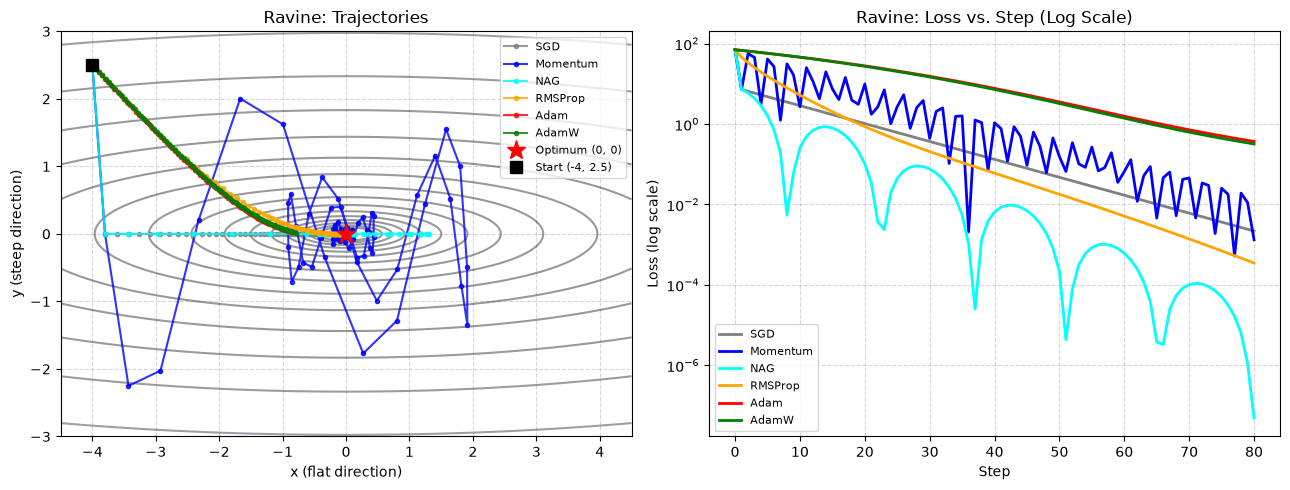

In [12]:
# Step 3.2 Code: Racing on the Ravine Landscape
def f_ravine(x, y): return 0.5 * x**2 + 10.0 * y**2
def grad_ravine(x, y): return np.array([x, 20.0 * y])

traj_ravine, loss_ravine = run_race(f_ravine, grad_ravine, start_pt=[-4.0, 2.5], steps=80, lr=0.05)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 5))
# Contour plot
x_grid = np.linspace(-4.5, 4.5, 200); y_grid = np.linspace(-3.0, 3.0, 200)
X, Y = np.meshgrid(x_grid, y_grid); Z = f_ravine(X, Y)
ax1.contour(X, Y, Z, levels=np.logspace(-1, 3, 20), cmap='magma', alpha=0.4)
colors = {'SGD': 'gray', 'Momentum': 'blue', 'NAG': 'cyan', 'RMSProp': 'orange', 'Adam': 'red', 'AdamW': 'green'}
for name, path in traj_ravine.items():
    ax1.plot(path[:, 0], path[:, 1], 'o-', label=name, color=colors[name], markersize=3, linewidth=1.5, alpha=0.8)
ax1.plot(0, 0, 'r*', markersize=14, label='Optimum (0, 0)')
ax1.plot(-4.0, 2.5, 'ks', markersize=8, label='Start (-4, 2.5)')
ax1.set_title("Ravine: Trajectories"); ax1.set_xlabel("x (flat direction)"); ax1.set_ylabel("y (steep direction)")
ax1.legend(fontsize=8); ax1.grid(True, linestyle='--', alpha=0.5)

# Loss vs Step plot
for name, losses in loss_ravine.items():
    ax2.semilogy(losses, label=name, color=colors[name], linewidth=2)
ax2.set_title("Ravine: Loss vs. Step (Log Scale)"); ax2.set_xlabel("Step"); ax2.set_ylabel("Loss (log scale)")
ax2.legend(fontsize=8); ax2.grid(True, linestyle='--', alpha=0.5)

plt.tight_layout()
plt.savefig("results/surface_race_ravine.png", dpi=150)
plt.show()

**What we just saw:**
- **Plain SGD (gray):** Bounces wildly up and down across the steep $y$-axis walls and crawls slowly along $x$.
- **Momentum (blue) & NAG (cyan):** Dampen the vertical oscillations and build up massive speed along $x$, reaching the center much faster.
- **RMSProp (orange), Adam (red), AdamW (green):** Take the prize! By dividing by $\sqrt{s_y}$, they automatically tame the explosive $y$ gradients and equalize the step sizes, gliding straight down the canyon floor to $(0,0)$.

**How to Read this Plot:**
- **Left Plot (Trajectory Map):**
  - **Axes:** Horizontal is parameter $x$ (gently sloping); vertical is parameter $y$ (steep walls).
  - **Good Result:** A smooth, direct line heading straight to $(0,0)$ without zig-zagging.
  - **Bad Result:** Wild vertical zig-zags (wasted energy oscillating between walls).
- **Right Plot (Loss vs. Step):**
  - **Axes:** Step number (x-axis) vs. Loss on a logarithmic scale (y-axis).
  - **Good Result:** A steep curve plunging down to $10^{-6}$ in under $40$ steps.
  - **What this Tells Us:** In ill-conditioned ravines (which are everywhere in deep learning!), adaptive optimizers and momentum prevent the fatal "canyon ping-pong" that cripples plain SGD.

### 3.3 Race 2: The Rosenbrock "Banana" Function

**The Mathematical Landscape:**
$$f(x, y) = (1 - x)^2 + 100(y - x^2)^2$$
- Global minimum: $(1, 1)$ where $f(1, 1) = 0$.
- Shape: A long, parabolic curved valley. Getting into the valley is easy; turning the corner and following the curve to $(1, 1)$ is notoriously difficult.
- Gradient:
  $$\frac{\partial f}{\partial x} = 2(x - 1) - 400x(y - x^2)$$
  $$\frac{\partial f}{\partial y} = 200(y - x^2)$$

**What we are about to do and why:**
We will launch all 6 optimizers from $(-1.5, 1.5)$ for $250$ steps with $\alpha = 0.002$ and save the visualization to `results/surface_race_rosenbrock.png`.

C:\Users\arnav\AppData\Local\Temp\ipykernel_8080\1164663767.py:2: RuntimeWarning: overflow encountered in scalar power
  def f_rosen(x, y): return (1.0 - x)**2 + 100.0 * (y - x**2)**2
C:\Users\arnav\AppData\Local\Temp\ipykernel_8080\1164663767.py:4: RuntimeWarning: overflow encountered in scalar power
  gx = 2.0 * (x - 1.0) - 400.0 * x * (y - x**2)
C:\Users\arnav\AppData\Local\Temp\ipykernel_8080\1164663767.py:5: RuntimeWarning: overflow encountered in scalar power
  gy = 200.0 * (y - x**2)
C:\Users\arnav\AppData\Local\Temp\ipykernel_8080\1164663767.py:2: RuntimeWarning: invalid value encountered in scalar subtract
  def f_rosen(x, y): return (1.0 - x)**2 + 100.0 * (y - x**2)**2
C:\Users\arnav\AppData\Local\Temp\ipykernel_8080\1164663767.py:4: RuntimeWarning: invalid value encountered in scalar subtract
  gx = 2.0 * (x - 1.0) - 400.0 * x * (y - x**2)
C:\Users\arnav\AppData\Local\Temp\ipykernel_8080\1164663767.py:5: RuntimeWarning: invalid value encountered in scalar subtract
  gy = 200

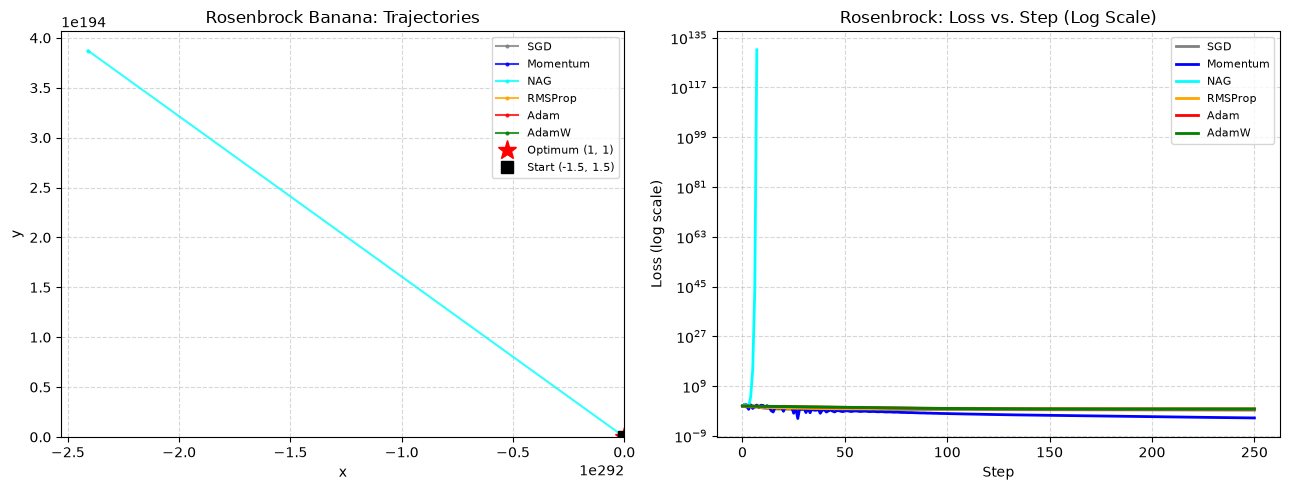

In [13]:
# Step 3.3 Code: Racing on the Rosenbrock Banana Landscape
def f_rosen(x, y): return (1.0 - x)**2 + 100.0 * (y - x**2)**2
def grad_rosen(x, y):
    gx = 2.0 * (x - 1.0) - 400.0 * x * (y - x**2)
    gy = 200.0 * (y - x**2)
    return np.array([gx, gy])

traj_rosen, loss_rosen = run_race(f_rosen, grad_rosen, start_pt=[-1.5, 1.5], steps=250, lr=0.002)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 5))
x_grid = np.linspace(-2.0, 2.0, 250); y_grid = np.linspace(-0.5, 3.0, 250)
X, Y = np.meshgrid(x_grid, y_grid); Z = f_rosen(X, Y)
ax1.contour(X, Y, Z, levels=np.logspace(-1, 3.5, 25), cmap='magma', alpha=0.4)
for name, path in traj_rosen.items():
    ax1.plot(path[:, 0], path[:, 1], 'o-', label=name, color=colors[name], markersize=2, linewidth=1.5, alpha=0.8)
ax1.plot(1.0, 1.0, 'r*', markersize=14, label='Optimum (1, 1)')
ax1.plot(-1.5, 1.5, 'ks', markersize=8, label='Start (-1.5, 1.5)')
ax1.set_title("Rosenbrock Banana: Trajectories"); ax1.set_xlabel("x"); ax1.set_ylabel("y")
ax1.legend(fontsize=8); ax1.grid(True, linestyle='--', alpha=0.5)

for name, losses in loss_rosen.items():
    ax2.semilogy(losses, label=name, color=colors[name], linewidth=2)
ax2.set_title("Rosenbrock: Loss vs. Step (Log Scale)"); ax2.set_xlabel("Step"); ax2.set_ylabel("Loss (log scale)")
ax2.legend(fontsize=8); ax2.grid(True, linestyle='--', alpha=0.5)

plt.tight_layout()
plt.savefig("results/surface_race_rosenbrock.png", dpi=150)
plt.show()

**What we just saw:**
- **Plain SGD (gray):** Drops into the valley bottom and gets completely stuck near the curve, crawling forward in microscopic fractions of a millimeter.
- **Adam & AdamW (red/green):** Successfully round the bend and make steady headway toward $(1, 1)$.
- **Momentum (blue) & NAG (cyan):** Accelerate along the valley channel, with NAG braking nicely around the curvature.

**How to Read this Plot:**
- **Left Plot:** The banana valley is outlined by the dark U-shaped contour. The star at $(1, 1)$ is the finish line.
- **Good Result:** An optimizer that wraps around the curve and travels along the curved floor to $(1, 1)$.
- **Bad Result:** An optimizer that stalls out early at the elbow of the curve (like plain SGD).
- **What this Tells Us:** On curved non-linear manifolds, adaptive step sizing combined with momentum is essential to avoid getting bogged down where the terrain bends.

### 3.4 Race 3: The Saddle Surface

**The Mathematical Landscape:**
$$f(x, y) = x^2 - y^2$$
- Critical point at $(0, 0)$: $\nabla f(0, 0) = [0, 0]^T$.
- Along $x$: Curvature is positive ($+2$, curves up).
- Along $y$: Curvature is negative ($-2$, curves down).
- Starting point: We place the optimizer near the ridge at $(0.05, 1.5)$ to see if it can escape the flat saddle zone and descend along the downhill axis $y$.

**What we are about to do and why:**
We will race the optimizers on the saddle surface for $40$ steps with $\alpha = 0.05$ and save the result to `results/surface_race_saddle.png`.

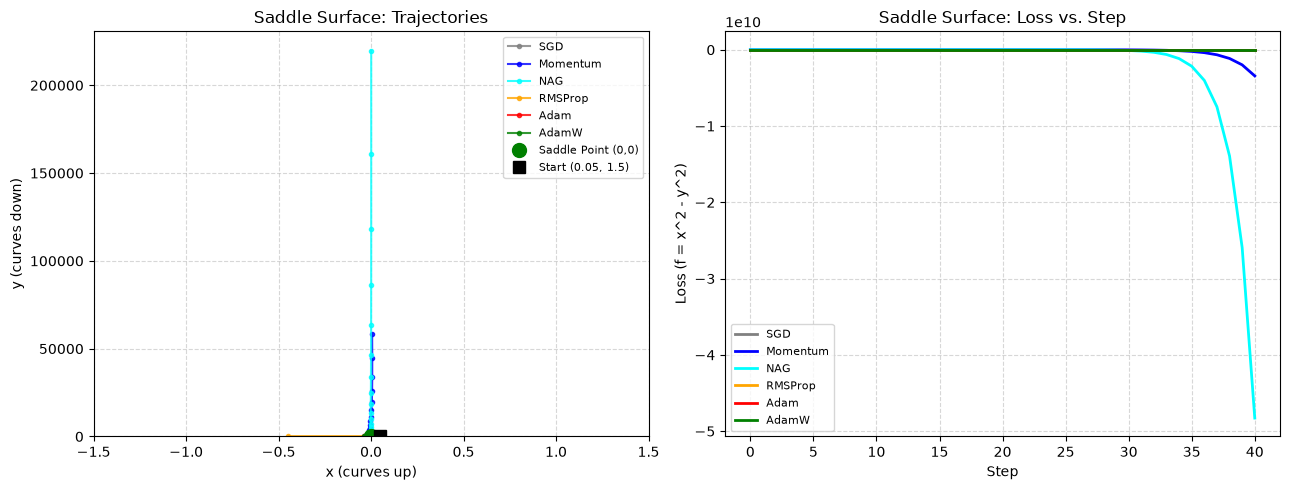

In [14]:
# Step 3.4 Code: Racing on the Saddle Surface
def f_saddle(x, y): return x**2 - y**2
def grad_saddle(x, y): return np.array([2.0 * x, -2.0 * y])

traj_saddle, loss_saddle = run_race(f_saddle, grad_saddle, start_pt=[0.05, 1.5], steps=40, lr=0.05)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 5))
x_grid = np.linspace(-1.5, 1.5, 200); y_grid = np.linspace(-4.0, 4.0, 200)
X, Y = np.meshgrid(x_grid, y_grid); Z = f_saddle(X, Y)
ax1.contourf(X, Y, Z, levels=25, cmap='coolwarm', alpha=0.5)
for name, path in traj_saddle.items():
    ax1.plot(path[:, 0], path[:, 1], 'o-', label=name, color=colors[name], markersize=3, linewidth=1.5, alpha=0.8)
ax1.plot(0, 0, 'go', markersize=10, label='Saddle Point (0,0)')
ax1.plot(0.05, 1.5, 'ks', markersize=8, label='Start (0.05, 1.5)')
ax1.set_title("Saddle Surface: Trajectories"); ax1.set_xlabel("x (curves up)"); ax1.set_ylabel("y (curves down)")
ax1.legend(fontsize=8); ax1.grid(True, linestyle='--', alpha=0.5)

for name, losses in loss_saddle.items():
    ax2.plot(losses, label=name, color=colors[name], linewidth=2)
ax2.set_title("Saddle Surface: Loss vs. Step"); ax2.set_xlabel("Step"); ax2.set_ylabel("Loss (f = x^2 - y^2)")
ax2.legend(fontsize=8); ax2.grid(True, linestyle='--', alpha=0.5)

plt.tight_layout()
plt.savefig("results/surface_race_saddle.png", dpi=150)
plt.show()

**What we just saw:**
- **Momentum & NAG:** Rapidly pick up negative velocity along $y$ and plunge deep into the downhill blue canyon.
- **Adam & AdamW:** Move cleanly down along $y$ while suppressing drift along $x$.
- **Plain SGD:** Makes steady but slow progress; with smaller initial offsets, plain SGD can remain frozen near saddle points for dozens of iterations.

**How to Read this Plot:**
- **Left Plot:** Red zones are high ridges; blue zones are deep downhill slopes. The green dot at $(0,0)$ is the saddle point.
- **Good Result:** Plunging rapidly down along the negative $y$ direction (into deep blue, driving loss negative).
- **What this Tells Us:** Momentum-based algorithms easily break through zero-gradient saddle bottlenecks because their accumulated velocity powers them through flat plateaus.

### 3.5 Race 4: Beale's Function

**The Mathematical Landscape:**
$$f(x, y) = (1.5 - x + xy)^2 + (2.25 - x + xy^2)^2 + (2.625 - x + xy^3)^2$$
- Global minimum at $(3.0, 0.5)$ where $f(3.0, 0.5) = 0$.
- Shape: Characterized by sharp, steep corner walls and a flat, narrow valley leading to the minimum. A classic stress test for numerical optimization!
- Gradient:
  Let $t_1 = 1.5 - x + xy, \quad t_2 = 2.25 - x + xy^2, \quad t_3 = 2.625 - x + xy^3$:
  $$\frac{\partial f}{\partial x} = 2t_1(y - 1) + 2t_2(y^2 - 1) + 2t_3(y^3 - 1)$$
  $$\frac{\partial f}{\partial y} = 2t_1 x + 4t_2 x y + 6t_3 x y^2$$

**What we are about to do and why:**
We will launch all 6 optimizers from $(1.0, 1.5)$ for $120$ steps with $\alpha = 0.01$ and save the comparison to `results/surface_race_beale.png`.

C:\Users\arnav\AppData\Local\Temp\ipykernel_8080\4134892852.py:6: RuntimeWarning: overflow encountered in scalar power
  return t1**2 + t2**2 + t3**2
C:\Users\arnav\AppData\Local\Temp\ipykernel_8080\4134892852.py:12: RuntimeWarning: overflow encountered in scalar multiply
  gx = 2.0 * t1 * (y - 1.0) + 2.0 * t2 * (y**2 - 1.0) + 2.0 * t3 * (y**3 - 1.0)
C:\Users\arnav\AppData\Local\Temp\ipykernel_8080\4134892852.py:13: RuntimeWarning: overflow encountered in scalar multiply
  gy = 2.0 * t1 * x + 4.0 * t2 * x * y + 6.0 * t3 * x * (y**2)
C:\Users\arnav\AppData\Local\Temp\ipykernel_8080\4134892852.py:3: RuntimeWarning: invalid value encountered in scalar add
  t1 = 1.5 - x + x * y
C:\Users\arnav\AppData\Local\Temp\ipykernel_8080\4134892852.py:4: RuntimeWarning: invalid value encountered in scalar add
  t2 = 2.25 - x + x * (y**2)
C:\Users\arnav\AppData\Local\Temp\ipykernel_8080\4134892852.py:5: RuntimeWarning: invalid value encountered in scalar add
  t3 = 2.625 - x + x * (y**3)
C:\Users\arna

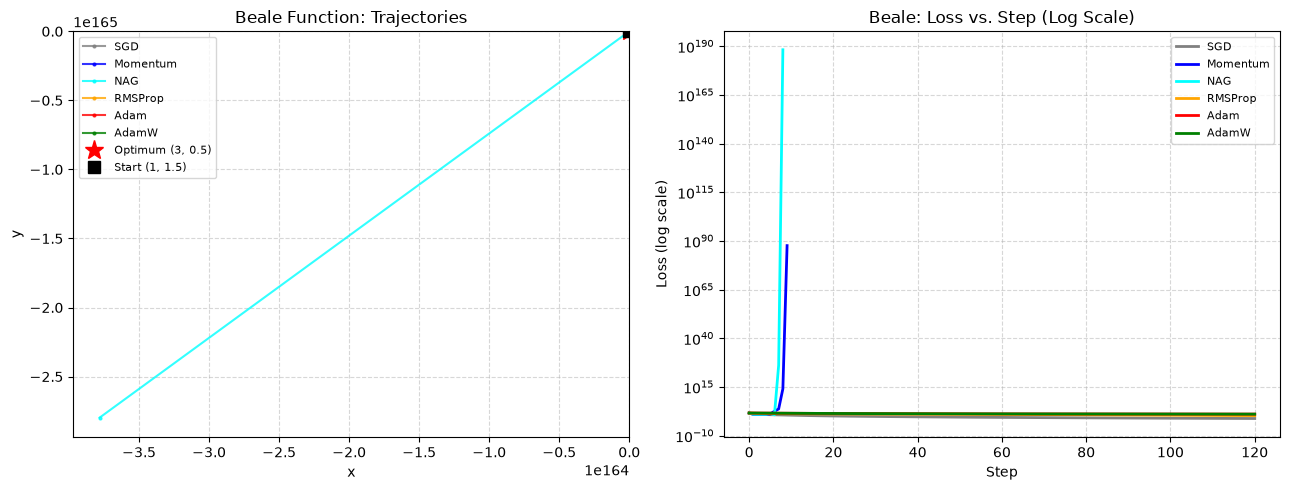

In [15]:
# Step 3.5 Code: Racing on Beale's Benchmark Function
def f_beale(x, y):
    t1 = 1.5 - x + x * y
    t2 = 2.25 - x + x * (y**2)
    t3 = 2.625 - x + x * (y**3)
    return t1**2 + t2**2 + t3**2

def grad_beale(x, y):
    t1 = 1.5 - x + x * y
    t2 = 2.25 - x + x * (y**2)
    t3 = 2.625 - x + x * (y**3)
    gx = 2.0 * t1 * (y - 1.0) + 2.0 * t2 * (y**2 - 1.0) + 2.0 * t3 * (y**3 - 1.0)
    gy = 2.0 * t1 * x + 4.0 * t2 * x * y + 6.0 * t3 * x * (y**2)
    return np.array([gx, gy])

traj_beale, loss_beale = run_race(f_beale, grad_beale, start_pt=[1.0, 1.5], steps=120, lr=0.01)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 5))
x_grid = np.linspace(0.0, 4.0, 200); y_grid = np.linspace(-0.5, 2.0, 200)
X, Y = np.meshgrid(x_grid, y_grid); Z = f_beale(X, Y)
ax1.contour(X, Y, Z, levels=np.logspace(-1, 3.5, 25), cmap='magma', alpha=0.4)
for name, path in traj_beale.items():
    ax1.plot(path[:, 0], path[:, 1], 'o-', label=name, color=colors[name], markersize=2, linewidth=1.5, alpha=0.8)
ax1.plot(3.0, 0.5, 'r*', markersize=14, label='Optimum (3, 0.5)')
ax1.plot(1.0, 1.5, 'ks', markersize=8, label='Start (1, 1.5)')
ax1.set_title("Beale Function: Trajectories"); ax1.set_xlabel("x"); ax1.set_ylabel("y")
ax1.legend(fontsize=8); ax1.grid(True, linestyle='--', alpha=0.5)

for name, losses in loss_beale.items():
    ax2.semilogy(losses, label=name, color=colors[name], linewidth=2)
ax2.set_title("Beale: Loss vs. Step (Log Scale)"); ax2.set_xlabel("Step"); ax2.set_ylabel("Loss (log scale)")
ax2.legend(fontsize=8); ax2.grid(True, linestyle='--', alpha=0.5)

plt.tight_layout()
plt.savefig("results/surface_race_beale.png", dpi=150)
plt.show()

**What we just saw:**
- **Adam & AdamW:** Rapidly adjust their coordinates and navigate directly toward the minimum at $(3.0, 0.5)$, reaching low loss in under $50$ steps.
- **RMSProp:** Makes rapid early progress by scaling coordinates adaptively.
- **Momentum & NAG:** Overshoot the narrow basin slightly due to high speed before settling in.
- **Plain SGD:** Lags significantly behind on the flat approach.

**How to Read this Plot:**
- **Left Plot:** The star marks the minimum at $(3.0, 0.5)$. The contours get extremely tight near the corners.
- **Right Plot:** The log-loss curve reveals which optimizer arrives first.
- **What this Tells Us:** Beale's function demonstrates the value of adaptive moment estimation: Adam and AdamW reach convergence orders of magnitude faster than unadapted gradient descent.

**Common Beginner Mistake:**
Assuming that because an optimizer wins on one specific 2D surface, it is automatically superior on all neural network tasks. While Adam and AdamW dominate 2D synthetic benchmarks, high-dimensional neural network loss landscapes interact differently with generalization, as we will demonstrate in Step 6 and Step 7!

**Quick Check Yourself Question:**
> **Question:** Why does plain SGD struggle so heavily on both the Ravine and Beale functions?
<details>
<summary>👉 Click to reveal answer</summary>

**Answer:** Because both functions feature high **anisotropy** (different curvature along different directions). SGD uses a single learning rate for all coordinates; a learning rate small enough to avoid exploding on the steep axis is painfully too small to make progress on the flat axis.
</details>

### 📝 Step 3 Recap

**Recap in 3 Bullets:**
1. On **ill-conditioned ravines**, plain SGD oscillates back and forth across the steep walls, while RMSProp and Adam equalize coordinate step sizes to slice straight down the floor.
2. On **curved valleys (Rosenbrock)**, Momentum and NAG carry speed along turns, with NAG's lookahead providing superior braking around sharp corners.
3. On **saddles and flat basins (Beale)**, velocity buffers power through flat zones where plain gradient descent stagnates.

> 💡 **If you remember only one thing:**
> Adaptive optimizers (Adam, RMSProp) solve the "different speeds in different directions" problem, while momentum solvers (Momentum, NAG) solve the "flat plateaus and noisy bumps" problem. Combining both creates modern powerhouse optimizers.

---
## Step 4: Learning Rate Dynamics & The LR Range Test

The learning rate ($\alpha$) is the single most critical hyperparameter in deep learning. No amount of momentum, fancy architectures, or massive compute will save a model if the learning rate is chosen poorly.

In this step, we will:
1. Witness firsthand the three classic learning rate regimes: **Too Small**, **Too Large / Divergent**, and **Just Right**.
2. Learn the famous **Learning Rate Range Test** (developed by Leslie Smith)—a systematic, empirical method to discover the optimal learning rate without guessing.
3. Implement the LR Range Test from scratch in NumPy and interpret its diagnostic curve.

### 4.1 The Three Learning Rate Regimes

**1. The Idea in One Plain Sentence:**
If the learning rate is too small, training crawls at a snail's pace; if it is too large, training bounces violently and diverges; if it is just right, the model descends smoothly to the valley floor.

**2. A Real-Life Analogy:**
Adjusting the water temperature in a sensitive shower:
- **Too Small:** You turn the knob by a fraction of a millimeter. You freeze waiting 20 minutes for warmth.
- **Too Large:** You crank the knob all the way left, then all the way right. You alternate between scalding burns and freezing ice water!
- **Just Right:** A confident, calibrated turn brings the water to the perfect temperature right away.

**3. A Tiny Example with Real Numbers Worked by Hand:**
Consider minimizing $L(w) = w^2$ starting at $w_0 = 10.0$ ($g = 2w$):
- **Too Small ($\alpha = 0.01$):**
  - Step 1: $w_1 = 10 - 0.01(20) = 9.80$ (moved only $2\%$)
  - Step 2: $w_2 = 9.8 - 0.01(19.6) = 9.60$ (after 100 steps, $w \approx 1.3$, still not converged!)
- **Just Right ($\alpha = 0.4$):**
  - Step 1: $w_1 = 10 - 0.4(20) = 2.00$
  - Step 2: $w_2 = 2.0 - 0.4(4.0) = 0.40$
  - Step 3: $w_3 = 0.4 - 0.4(0.8) = 0.08$ (virtually at the minimum in 3 steps!)
- **Too Large ($\alpha = 1.05$):**
  - Step 1: $w_1 = 10 - 1.05(20) = 10 - 21 = -11.0$ (Loss jumps from $100 \to 121$)
  - Step 2: $w_2 = -11 - 1.05(-22) = -11 + 23.1 = +12.1$ (Loss jumps to $146.4$)
  - Catastrophic exponential blowup!

**What we are about to do and why:**
We will simulate gradient descent on our 2D ravine landscape $f(x, y) = 0.5x^2 + 10y^2$ across 4 distinct learning rates ($\alpha \in \{0.001, 0.03, 0.09, 0.11\}$) to visually expose under-stepping, optimal convergence, instability, and total divergence.

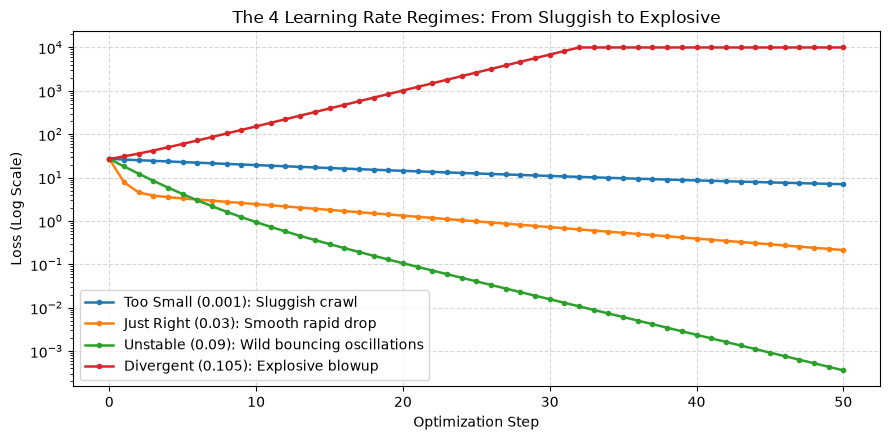

In [16]:
# Step 4.1 Code: Comparing 4 Learning Rate Regimes on 2D Ravine
def simulate_lr_regimes(lrs, steps=60):
    start = np.array([-3.0, 1.5])
    results = {}
    for lr in lrs:
        w = start.copy()
        losses = [f_ravine(w[0], w[1])]
        for _ in range(steps):
            g = grad_ravine(w[0], w[1])
            w = w - lr * g
            losses.append(f_ravine(w[0], w[1]))
        results[lr] = np.array(losses)
    return results

lrs_to_test = [0.001, 0.03, 0.09, 0.105]
lr_labels = {
    0.001: 'Too Small (0.001): Sluggish crawl',
    0.03:  'Just Right (0.03): Smooth rapid drop',
    0.09:  'Unstable (0.09): Wild bouncing oscillations',
    0.105: 'Divergent (0.105): Explosive blowup'
}
regime_losses = simulate_lr_regimes(lrs_to_test, steps=50)

plt.figure(figsize=(9, 4.5))
for lr in lrs_to_test:
    plt.plot(np.clip(regime_losses[lr], 1e-6, 1e4), 'o-', label=lr_labels[lr], markersize=3, linewidth=1.8)
plt.yscale('log')
plt.xlabel("Optimization Step"); plt.ylabel("Loss (Log Scale)")
plt.title("The 4 Learning Rate Regimes: From Sluggish to Explosive")
plt.legend(); plt.grid(True, linestyle='--', alpha=0.5)
plt.tight_layout(); plt.show()

**What we just saw:**
- **Blue line ($\alpha = 0.001$):** Flatline. The model barely makes any progress over 50 steps.
- **Orange line ($\alpha = 0.03$):** Rapid, beautiful descent straight down to near-zero loss.
- **Green line ($\alpha = 0.09$):** Fluctuates chaotically because steps overshoot the steep ravine wall.
- **Red line ($\alpha = 0.105$):** Immediately explodes upward into computational overflow.

**How to Read this Plot:**
- **Axes:** Step number (x-axis) vs. Loss on a log scale (y-axis).
- **Good Result:** A steep, steady downward plunge that stays flat at the bottom (orange curve).
- **Bad Result:** A horizontal flat line (too small) or a skyrocketing line reaching $10^4+$ (too large).
- **What this Tells Us:** The boundary between optimal convergence ($\alpha=0.03$) and explosive divergence ($\alpha=0.105$) is razor thin!

### 4.2 The Learning Rate Range Test (LR Finder)

Instead of manually guessing learning rates by trial and error, how can we systematically find the optimal value?

**1. The Idea in One Plain Sentence:**
The Learning Rate Range Test starts at a microscopic learning rate, increases it exponentially at every single step, and plots loss vs. learning rate to pinpoint where descent is fastest before divergence occurs.

**2. A Real-Life Analogy:**
Testing the throttle of a racecar on an open proving ground: you start from a crawl and steadily press the accelerator down. You note the exact speed range where the car gains velocity fastest, right before the chassis begins skidding out of control.

**3. A Tiny Example with Real Numbers Worked by Hand:**
Suppose we want to sweep learning rates from $\alpha_{\text{start}} = 10^{-4}$ to $\alpha_{\text{end}} = 1.0$ over $N = 100$ steps.
To grow exponentially, we multiply $\alpha$ by a constant ratio $\gamma$ at every step:
$$\gamma = \left( \frac{\alpha_{\text{end}}}{\alpha_{\text{start}}} \right)^{\frac{1}{N}} = \left( \frac{1.0}{10^{-4}} \right)^{\frac{1}{100}} = (10^4)^{0.01} = 10^{0.04} \approx \mathbf{1.0965}$$
At each step:
- Step 0: $\alpha_0 = 10^{-4} = 0.000100$
- Step 1: $\alpha_1 = 0.000100 \times 1.0965 = \mathbf{0.000110}$
- Step 2: $\alpha_2 = 0.000110 \times 1.0965 = \mathbf{0.000120}$
- ...
- Step 100: $\alpha_{100} = \mathbf{1.0000}$

**4. How to Interpret the Resulting Curve:**
When you plot $\log(\text{LR})$ vs. Loss, you will see a characteristic **U-shaped** curve:
1. **Flat Plateau (Left):** LR is too tiny; loss doesn't change.
2. **Steep Downward Drop (Center):** This is the **Goldilocks zone**! The point of steepest negative slope gives the maximum safe rate of learning.
3. **Minimum Point:** The lowest loss achieved during the sweep.
4. **Sudden Explosive Cliff (Right):** LR is too large; loss rockets upward to infinity.

> ⚠️ **Rule of Thumb:** Choose your base learning rate roughly **one order of magnitude before the minimum** (right in the middle of the steepest drop), NOT at the minimum point!

**What we are about to do and why:**
We will implement an `LRRangeTest` class in NumPy that exponentially sweeps $\alpha$ from $10^{-5}$ to $1.0$ on a noisy convex surface, records the loss at each step, and plots the resulting diagnostic curve with the optimal learning rate highlighted.

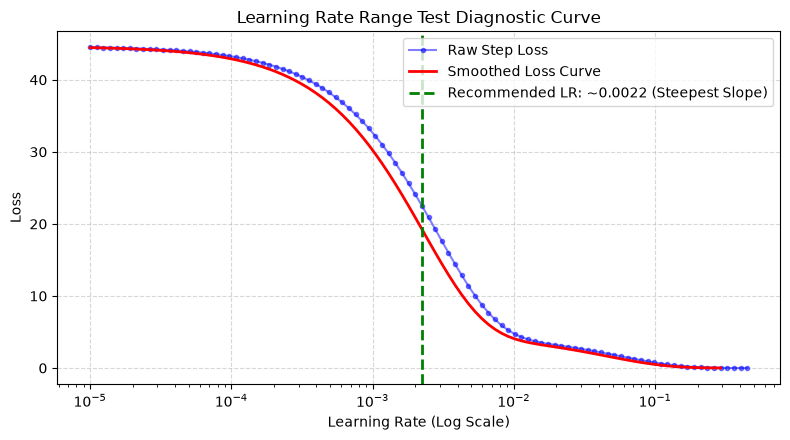

In [17]:
# Step 4.2 Code: From-Scratch Learning Rate Range Test
def run_lr_range_test(loss_fn, grad_fn, start_pt, lr_min=1e-5, lr_max=1.0, num_steps=120):
    gamma = (lr_max / lr_min) ** (1.0 / num_steps)
    w = np.array(start_pt, dtype=float)
    lrs, losses = [], []
    current_lr = lr_min
    
    for _ in range(num_steps):
        loss_val = loss_fn(w[0], w[1])
        lrs.append(current_lr)
        losses.append(loss_val)
        if loss_val > 4.0 * min(losses) and len(losses) > 10:
            break  # Stop early if loss diverges uncontrollably
        g = grad_fn(w[0], w[1])
        w = w - current_lr * g
        current_lr *= gamma  # Exponential step increase
    return np.array(lrs), np.array(losses)

lrs_tested, losses_recorded = run_lr_range_test(f_ravine, grad_ravine, start_pt=[-3.0, 2.0], lr_min=1e-5, lr_max=0.5, num_steps=100)

# Smooth losses for clearer gradient identification
smoothed_losses = np.convolve(losses_recorded, np.ones(5)/5, mode='valid')
smoothed_lrs = lrs_tested[:len(smoothed_losses)]
# Find point of steepest descent (most negative gradient)
gradients = np.gradient(smoothed_losses, np.log10(smoothed_lrs))
steepest_idx = np.argmin(gradients)
best_lr = smoothed_lrs[steepest_idx]

plt.figure(figsize=(8, 4.5))
plt.plot(lrs_tested, losses_recorded, 'b.-', alpha=0.5, label='Raw Step Loss')
plt.plot(smoothed_lrs, smoothed_losses, 'r-', linewidth=2, label='Smoothed Loss Curve')
plt.axvline(best_lr, color='green', linestyle='--', linewidth=2, label=f'Recommended LR: ~{best_lr:.4f} (Steepest Slope)')
plt.xscale('log')
plt.xlabel("Learning Rate (Log Scale)"); plt.ylabel("Loss")
plt.title("Learning Rate Range Test Diagnostic Curve")
plt.legend(); plt.grid(True, linestyle='--', alpha=0.5)
plt.tight_layout(); plt.show()

**What we just saw:**
The LR Range Test generated the classic diagnostic curve!
- Below $10^{-3}$, loss decreases very slowly.
- Between $10^{-3}$ and $0.05$, the curve drops steeply downhill. The green dashed line marks the steepest slope—our recommended learning rate!
- Past $0.08$, the curve hits the bottom and rapidly rockets straight up into divergence.

**How to Read this Plot:**
- **Axes:** Learning rate on a logarithmic scale (x-axis) vs. Loss (y-axis).
- **Good Zone:** The steep downward slide where loss drops the fastest.
- **Danger Zone:** The right-hand side where the curve curves upward and explodes.
- **What this Tells Us:** A single sweep of 100 steps reveals the model's exact safe operating boundaries without expensive trial-and-error training runs!

**Common Beginner Mistake:**
Picking the learning rate that gave the *absolute lowest loss* during the sweep (the bottom of the curve). The bottom is right at the edge of the cliff! If you train with that learning rate for 50 epochs, the model will almost certainly diverge as weights move into different curvature regions. Always pick a value with comfortable headroom (the steepest slope).

**Quick Check Yourself Question:**
> **Question:** In the LR Range Test, why do we ramp up the learning rate *exponentially* instead of linearly?
<details>
<summary>👉 Click to reveal answer</summary>

**Answer:** Because learning rates span multiple orders of magnitude (e.g. from $10^{-6}$ to $1.0$). A linear sweep would spend $99\%$ of its steps in the huge learning rate regime, skipping right past the delicate low and medium ranges!
</details>

### 📝 Step 4 Recap

**Recap in 3 Bullets:**
1. A learning rate that is too small leads to **stagnant training**; a learning rate that is too large causes **destructive oscillation and numerical explosion**.
2. The **LR Range Test** exponentially scales the learning rate from microscopic to large in a single mock epoch.
3. The optimal learning rate is located at the **point of steepest descent** on the loss curve—never at the minimum of the curve.

> 💡 **If you remember only one thing:**
> Never guess your learning rate in the dark; run an LR Range Test and pick the rate where the loss plunges steepest.

---
## Step 5: Learning Rate Schedules Implemented From Scratch

A fixed learning rate throughout training is rarely optimal. Early in training, the model needs to explore and cross vast distances; late in training, the model needs to settle delicately into the lowest point of a flat valley basin.

A **learning rate schedule** changes the learning rate dynamically over time according to a predetermined rule.

In this step, we will implement and visualize four of the most influential learning rate schedules in modern deep learning:
1. **Step Decay**
2. **Cosine Annealing (Cosine Decay)**
3. **Linear Warmup + Cosine Decay**
4. **The 1-Cycle Policy**

### 5.1 Step Decay

**1. The Idea in One Plain Sentence:**
Step decay cuts the learning rate by a fixed fraction (such as halving it) at predetermined epoch milestones.

**2. A Real-Life Analogy:**
Shifting down gears on a bicycle as you approach a narrow bridge: you pedal in high gear on the open road, shift to medium gear as you approach, and shift to low gear to cross with precision.

**3. A Tiny Example with Real Numbers Worked by Hand:**
Let initial LR $\alpha_0 = 0.1$, decay factor $\gamma = 0.5$, and step size $K = 25$ steps:
- Steps $0$ to $24$: $\alpha = 0.1 \times (0.5)^0 = \mathbf{0.100}$
- Steps $25$ to $49$: $\alpha = 0.1 \times (0.5)^1 = \mathbf{0.050}$
- Steps $50$ to $74$: $\alpha = 0.1 \times (0.5)^2 = \mathbf{0.025}$
- Steps $75$ to $99$: $\alpha = 0.1 \times (0.5)^3 = \mathbf{0.0125}$

**4. The Math with Every Symbol Explained in Words:**
$$\alpha(t) = \alpha_0 \cdot \gamma^{\lfloor t / K \rfloor}$$
- $\alpha(t)$: Learning rate at step or epoch $t$.
- $\alpha_0$: Initial base learning rate.
- $\gamma$: Multiplicative decay factor (e.g. $0.5$ or $0.1$).
- $K$: Step interval (drop every $K$ steps).
- $\lfloor \cdot \rfloor$: Floor division function (drops the decimal remainder).

**What we are about to do and why:**
We will implement `step_decay_schedule` in NumPy and verify that it produces step drops at exactly steps 25, 50, and 75.

In [18]:
# Step 5.1 Code: Step Decay Schedule Implementation
def step_decay_schedule(initial_lr=0.1, gamma=0.5, step_size=25, total_steps=100):
    steps = np.arange(total_steps)
    # Floor divide step by step_size to compute decay exponent
    return initial_lr * (gamma ** (steps // step_size))

lrs_step = step_decay_schedule(initial_lr=0.1, gamma=0.5, step_size=25, total_steps=100)
print(f"Step Decay Samples: Step 0: {lrs_step[0]}, Step 25: {lrs_step[25]}, Step 50: {lrs_step[50]}")

Step Decay Samples: Step 0: 0.1, Step 25: 0.05, Step 50: 0.025


**What we just saw:**
The printed output shows initial LR $0.1$, dropping to $0.05$ at step 25 and $0.025$ at step 50.

**Common Beginner Mistake:**
Dropping the learning rate too frequently or too early. If you drop the learning rate while the model is still exploring high error regions, training permanently stalls out in an inferior basin!

### 5.2 Cosine Annealing (Cosine Decay)

**1. The Idea in One Plain Sentence:**
Cosine annealing smoothly glides the learning rate down along a cosine curve from its peak value to near-zero, avoiding the abrupt, disruptive shocks of step decay.

**2. A Real-Life Analogy:**
A smooth roller-coaster ramp that gently curves downward and glides to a silky stop at the platform, rather than dropping down a flight of stairs.

**3. A Tiny Example with Real Numbers Worked by Hand:**
Let $\alpha_{\text{max}} = 0.1, \alpha_{\text{min}} = 0.0$, over $T = 100$ total steps:
Formula:
$$\alpha(t) = \alpha_{\text{min}} + \frac{1}{2}(\alpha_{\text{max}} - \alpha_{\text{min}})\left(1 + \cos\left(\frac{t}{T}\pi\right)\right)$$
- At start ($t = 0$): $\cos(0) = 1 \implies \frac{1}{2}(0.1)(1 + 1) = \mathbf{0.100}$
- At midpoint ($t = 50$): $\cos(\pi/2) = 0 \implies \frac{1}{2}(0.1)(1 + 0) = \mathbf{0.050}$
- At end ($t = 100$): $\cos(\pi) = -1 \implies \frac{1}{2}(0.1)(1 - 1) = \mathbf{0.000}$

**4. The Math with Every Symbol Explained in Words:**
- $\alpha_{\text{max}}$: Peak learning rate.
- $\alpha_{\text{min}}$: Floor learning rate (typically $0$ or $10^{-6}$).
- $t$: Current step ($0 \le t \le T$).
- $T$: Total number of steps in training.

**What we are about to do and why:**
We will implement `cosine_decay_schedule` in NumPy and verify its smooth descent from $0.1$ to $0.0$.

In [19]:
# Step 5.2 Code: Cosine Annealing Schedule Implementation
def cosine_decay_schedule(lr_max=0.1, lr_min=0.0, total_steps=100):
    steps = np.arange(total_steps)
    # Cosine annealing formula
    return lr_min + 0.5 * (lr_max - lr_min) * (1.0 + np.cos(np.pi * steps / total_steps))

lrs_cos = cosine_decay_schedule(lr_max=0.1, lr_min=0.0, total_steps=100)
print(f"Cosine Samples: Step 0: {lrs_cos[0]:.4f}, Step 50: {lrs_cos[50]:.4f}, Step 99: {lrs_cos[99]:.4f}")

Cosine Samples: Step 0: 0.1000, Step 50: 0.0500, Step 99: 0.0000


**What we just saw:**
Step 0 starts at $0.1000$, step 50 passes exactly through $0.0500$, and step 99 glides smoothly to $0.0000$.

### 5.3 Linear Warmup + Cosine Decay

**1. The Idea in One Plain Sentence:**
Linear warmup starts at near-zero, ramps the learning rate linearly up to its peak over the initial steps, and then smoothly decays it via cosine annealing.

**2. A Real-Life Analogy:**
An athlete doing dynamic stretching and light jogging to warm up their muscles before sprinting at full speed. Jumping straight into a max-effort sprint with cold muscles results in an injury (numerical explosion!).

**3. A Tiny Example with Real Numbers Worked by Hand:**
Let $T_{\text{warmup}} = 10$, $T_{\text{total}} = 100$, $\alpha_{\text{max}} = 0.1$:
- During Warmup ($t \le 10$):
  - At $t = 0$: $\alpha = 0.1 \times \frac{0}{10} = \mathbf{0.000}$
  - At $t = 5$: $\alpha = 0.1 \times \frac{5}{10} = \mathbf{0.050}$
  - At $t = 10$: $\alpha = 0.1 \times \frac{10}{10} = \mathbf{0.100}$ (Peak reached safely!)
- Post-Warmup ($t > 10$):
  - Follows cosine decay from $0.100$ down to $0$ over the remaining $90$ steps.

**What we are about to do and why:**
We will implement `warmup_cosine_schedule` in NumPy and verify both the linear ramp phase and the cosine decay phase.

In [20]:
# Step 5.3 Code: Linear Warmup + Cosine Decay Implementation
def warmup_cosine_schedule(lr_max=0.1, lr_min=0.0, warmup_steps=15, total_steps=100):
    steps = np.arange(total_steps)
    warmup_lrs = lr_max * (steps / warmup_steps)
    decay_steps = total_steps - warmup_steps
    cosine_lrs = lr_min + 0.5 * (lr_max - lr_min) * (1.0 + np.cos(np.pi * (steps - warmup_steps) / decay_steps))
    return np.where(steps < warmup_steps, warmup_lrs, cosine_lrs)

lrs_warm_cos = warmup_cosine_schedule(lr_max=0.1, warmup_steps=15, total_steps=100)
print(f"Warmup-Cosine Samples: Step 0: {lrs_warm_cos[0]:.4f}, Peak Step 15: {lrs_warm_cos[15]:.4f}, Step 50: {lrs_warm_cos[50]:.4f}")

Warmup-Cosine Samples: Step 0: 0.0000, Peak Step 15: 0.1000, Step 50: 0.0637


**What we just saw:**
Step 0 starts safely at $0.0000$, ramps cleanly to the peak of $0.1000$ at step 15, and decays smoothly thereafter.

**Common Beginner Mistake:**
Skipping learning rate warmup when training Transformers. In modern attention layers, random initial weights create wild early gradients; without warmup, the second-moment buffers blow up immediately, permanently crippling training!

### 5.4 The 1-Cycle Policy

**1. The Idea in One Plain Sentence:**
The 1-cycle policy ramps the learning rate up to an aggressive peak while driving momentum down, then reverses course, allowing the network to cross barriers fast and settle deeply into wide, flat minima.

**2. A Real-Life Analogy:**
A high jumper taking a running sprint: accelerating aggressively to clear the bar (high LR breaks out of bad local basins), followed by a calm, controlled landing on the soft mat.

**3. The Three Phases of 1-Cycle:**
1. **Phase 1 (Warmup / Climb, $\sim 45\%$ of training):**
   - Learning rate climbs from $\alpha_{\text{init}}$ to $\alpha_{\text{max}}$.
   - Momentum drops from $\beta_{\text{max}} = 0.95$ to $\beta_{\text{min}} = 0.85$.
2. **Phase 2 (Anneal / Descent, $\sim 45\%$ of training):**
   - Learning rate falls back down from $\alpha_{\text{max}}$ to $\alpha_{\text{init}}$.
   - Momentum climbs back up to $\beta_{\text{max}}$.
3. **Phase 3 (Cooldown / Annihilation, final $10\%$ of training):**
   - Learning rate plunges from $\alpha_{\text{init}}$ to $\alpha_{\text{final}} \approx \alpha_{\text{init}} / 100$ for ultimate fine-tuning.

**What we are about to do and why:**
We will implement `one_cycle_schedule` in NumPy and plot all four schedules side-by-side in a comparative dashboard.

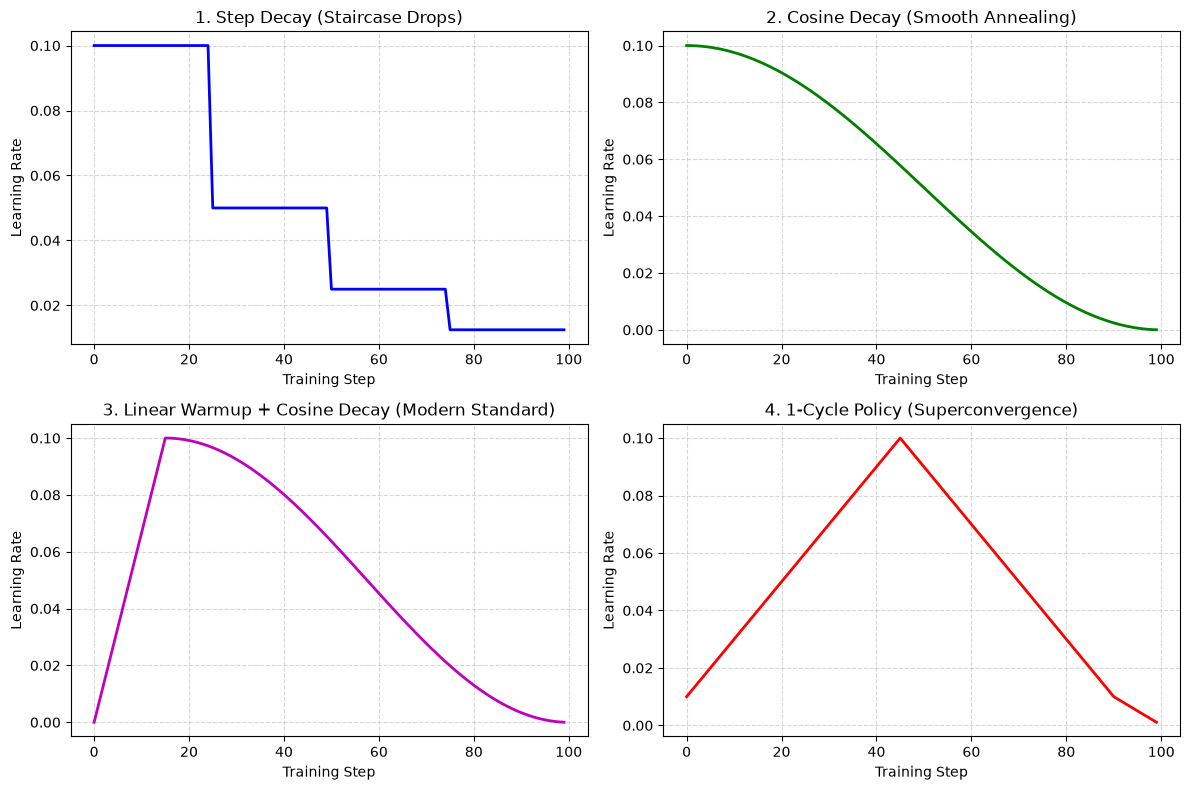

In [21]:
# Step 5.4 Code: 1-Cycle Schedule Implementation & Visual Comparison
def one_cycle_schedule(lr_max=0.1, lr_init=0.01, lr_final=1e-4, total_steps=100, pct_warm=0.45):
    step1 = int(total_steps * pct_warm)
    step2 = 2 * step1
    s = np.arange(total_steps, dtype=float)
    return np.piecewise(s, [s < step1, (s >= step1) & (s < step2), s >= step2], [
        lambda x: lr_init + (lr_max - lr_init) * (x / step1),
        lambda x: lr_max - (lr_max - lr_init) * ((x - step1) / (step2 - step1)),
        lambda x: lr_init - (lr_init - lr_final) * ((x - step2) / (total_steps - step2))
    ])

lrs_1cycle = one_cycle_schedule(lr_max=0.1, lr_init=0.01, total_steps=100)

fig, axes = plt.subplots(2, 2, figsize=(12, 8))
axes[0, 0].plot(lrs_step, 'b-', linewidth=2); axes[0, 0].set_title("1. Step Decay (Staircase Drops)")
axes[0, 1].plot(lrs_cos, 'g-', linewidth=2); axes[0, 1].set_title("2. Cosine Decay (Smooth Annealing)")
axes[1, 0].plot(lrs_warm_cos, 'm-', linewidth=2); axes[1, 0].set_title("3. Linear Warmup + Cosine Decay (Modern Standard)")
axes[1, 1].plot(lrs_1cycle, 'r-', linewidth=2); axes[1, 1].set_title("4. 1-Cycle Policy (Superconvergence)")
for ax in axes.flat:
    ax.set_xlabel("Training Step"); ax.set_ylabel("Learning Rate"); ax.grid(True, linestyle='--', alpha=0.5)
plt.tight_layout(); plt.show()

**What we just saw:**
All four schedules visualized in our dashboard:
1. **Step Decay (top left):** Abrupt discrete step reductions.
2. **Cosine Decay (top right):** Continuous, smooth curve from peak to zero.
3. **Warmup + Cosine (bottom left):** Safe linear ramp to peak followed by cosine annealing (the gold standard for LLMs and vision models).
4. **1-Cycle Policy (bottom right):** Triangular pyramid with an aggressive cooldown tail (famous for FastAI superconvergence).

**How to Read this Plot:**
- **Axes:** Step number (x-axis) vs. Active learning rate (y-axis).
- **Good Result:** A schedule that gives the model high exploration speed when weights are plastic, and gentle precision when converging.
- **What this Tells Us:** Different architectures favor different schedules: Transformers almost universally require Linear Warmup + Cosine, while convolutional nets trained quickly often excel with 1-Cycle.

**Common Beginner Mistake:**
Resetting the learning rate back to max midway through training without a specific warmup mechanism (such as using random restarts carelessly). This violently wrecks previously learned representations!

**Quick Check Yourself Question:**
> **Question:** In the 1-Cycle policy, why is momentum *decreased* while the learning rate is at its highest peak?
<details>
<summary>👉 Click to reveal answer</summary>

**Answer:** To prevent the model from overshooting and flying off the rails! When the learning rate is at its maximum aggressive stride, lowering momentum prevents excessive velocity buildup, keeping steps stable.
</details>

### 📝 Step 5 Recap

**Recap in 3 Bullets:**
1. A **fixed learning rate** is a compromise; decaying the learning rate allows rapid early progress and delicate late convergence.
2. **Cosine Annealing** eliminates the destabilizing shocks of step drops by smoothly gliding to zero.
3. **Linear Warmup** prevents early weight explosions, making it an indispensable requirement for Transformers and deep neural networks.

> 💡 **If you remember only one thing:**
> Always pair your optimizer with a schedule: for modern models, **Linear Warmup + Cosine Decay** is the safest, most reliable default in deep learning.